<a href="https://colab.research.google.com/github/Gaenariya/Ai/blob/main/24_%EC%B5%9C%EC%A2%85_AI%EC%84%9C%EB%B2%84.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 24. 최종 AI 서버 — 23번까지의 기능 전부 + 벽 면 나누기 (FastAPI)
20번(백엔드에 이미 넘긴 서버)의 **주소와 요청 모양을 그대로 유지**하면서, 21~23번에서 만든 것(가장자리 정확도, 해상도 분리, 천장·몰딩, 벽 무늬 지우기, **벽지 사진 덮어씌우기**)과 **벽 면 분리(wall1·wall2·wall3)**를 넣은 **최종 서버**임
→ 백엔드가 20번에 맞춰 짜 둔 코드는 **고치지 않아도 그대로 동작함**. 새 기능은 전부 추가(선택)임

```
사진 업로드 → [POST /rooms] 영역 분할 1번 → room_id + 영역 목록(벽 면 포함)
(선택) 붓 수정 → [POST /rooms/{id}/edits] / 모서리 직접 지정 → [POST /rooms/{id}/wall-split]
(선택) 레퍼런스 분석 → [POST /recommend] → 키워드 + 시안(벽 색 또는 벽지 id + 바닥재 id)
시안 생성 → [POST /rooms/{id}/generate] → 이미지 (면마다 다른 재료도 가능, 몇 번이든 다시 호출)
```

## 20번과 달라진 점 (백엔드가 새로 쓸 수 있는 것)
| 새로 생긴 것 | 설명 |
|---|---|
| **벽 면 분리** | `POST /rooms` 응답에 `wall_faces: ["wall1","wall2","wall3"]`(왼쪽부터)와 영역 번호 11, 12, 13이 들어옴 |
| `POST /rooms/{id}/wall-split` | 모서리를 자동 추정이 아니라 `{"x": [400, 1500]}`으로 직접 지정 (사용자가 화면에서 선을 끌 때) |
| **면마다 다른 재료** | `materials`에 `{"wall1": {...}, "wall2": {...}}`. `allWalls`와 같이 주면 **개별 면이 우선**, 안 준 면은 `allWalls`로 칠함 |
| **벽지 사진 합성** | `POST /walls/sync`로 벽지 목록을 등록하면 벽을 색이 아니라 **진짜 벽지 사진**으로 덮음 (원근·빛 반영) |
| **무늬 자동 판단** | 면마다 무늬 점수를 재서 **무늬가 있으면 덮어씌우고(overlay), 민무늬면 필터(filter)**로 칠함. `POST /rooms` 응답의 `wall_methods`, `options.wall_method`로 확인·고정 |
| **천장 / 몰딩** | `materials`의 `ceiling`, `moldingTop`, `moldingBottom` (영역 번호 3, 4, 5) |
| **옛 무늬 지우기** | `options.pattern` (0~1). 덮어씌울 때만 씀 (필터에서는 원래 결을 그대로 둠) |
| 벽 조절값 | `options.wall_tile`(벽지 크기), `wall_keep`(원래 빛 유지), `wall_spec`, `wall_exposure` |
| 결과 품질 | `preview: true`(긴 변 512px로 작게 — 슬라이더 미리보기용), `quality`(JPEG 품질) |

**영역 번호** (`GET /rooms/{id}/regions?kind=ids`의 픽셀 값)
- `0` 없음(지우개) · `1` allWalls(벽 전체) · `2` floor · `3` ceiling · `4` moldingTop(천장 몰딩) · `5` moldingBottom(걸레받이)
- `11`, `12`, `13` … = `wall1`, `wall2`, `wall3` … (**왼쪽부터** 번호)

**벽 칠하는 두 가지 방식** (`wall_methods`)
- `overlay`(덮어씌우기): 바닥재처럼 새 재료를 깔고 **원래 방의 빛만** 가져옴 → 꽃무늬가 완전히 사라짐
- `filter`(필터): 원래 벽의 결·굴곡을 그대로 곱함 → 민무늬 벽에서 가장 자연스러움
- 기본은 `auto` (무늬 점수로 면마다 판단). 벽지 '사진'을 쓸 때는 언제나 `overlay`

**벽을 못 나누는 사진** (정면 벽 한 면만 보이거나 가구가 바닥선을 다 가린 경우)
- `wall_split_found: false`, `wall_faces: ["wall1"]` → **벽 전체가 wall1 하나**가 됨. 백엔드·프론트는 그냥 면이 1개인 방으로 다루면 됨
- 사용자가 직접 나누고 싶으면 `POST /rooms/{id}/wall-split`

## 서버 쓰는 법
- 인증: 요청 헤더 `X-AI-Key: <비밀 값>` (Colab 🔑에 `AI_SERVER_KEY`로 저장, 백엔드와 같은 값). `/health`만 인증 없이 열림
- 명세: 서버를 켜면 **`주소/docs`**에서 바로 보고 실행해 볼 수 있음 (백엔드·프론트 공유용)
- 에러: `{"error": {"code": "...", "message": "...", "details": null}}`
- 방(room)은 서버 메모리에 최근 30개만 남음. 서버를 다시 켜면 사라지므로 `room_not_found`(404)면 `POST /rooms`로 다시 올리면 됨
- 임시 주소(trycloudflare)는 **서버를 다시 켤 때마다 바뀜** → 백엔드에 다시 알려줘야 함
- Colab 무료는 **GPU 런타임을 한 번에 하나만** 쓸 수 있음 → 이 노트북을 켜면 다른 노트북(23번 등)은 끊김

| 요청 | 하는 일 |
|---|---|
| `GET /health` | 연결 확인 |
| `POST /floors/sync` · `GET /floors` | 바닥재 목록 등록 / 확인 |
| `POST /walls/sync` · `GET /walls` | 벽지 목록 등록 / 확인 (등록하면 벽지 사진 합성이 켜짐) |
| `POST /rooms` | 방 사진 → 영역 분할 + 벽 면 + 몰딩 → `room_id` |
| `GET /rooms/{id}` | 방 정보 |
| `GET /rooms/{id}/regions?kind=overlay\|ids` | 영역 그림 |
| `POST /rooms/{id}/edits` | 붓 수정 (좌표는 원본 사진 픽셀) |
| `POST /rooms/{id}/wall-split` | 벽 모서리 직접 지정 |
| `POST /rooms/{id}/reset` | 수정 되돌리기 |
| `POST /recommend` | 레퍼런스 사진 → 키워드 + 시안 N개 |
| `POST /rooms/{id}/generate` | 재료를 입힌 이미지(`image_base64`) |
| `DELETE /rooms/{id}` | 방 지우기 |

**아직 못 하는 것 (솔직하게)**
- 가구·창문·문은 그대로 둠 (가구 바꾸기, 가구 지우기는 안 됨)
- 천장 몰딩과 걸레받이를 **서로 다른 재료**로는 아직 못 칠함 (하나로만)
- 방 기억이 메모리에만 있음 → 서버 여러 대로 늘리려면 Redis 같은 걸로 옮겨야 함
- **실제 사진·실제 OpenAI·실제 CLIP으로는 아직 한 번도 돌려보지 못했음** (여기 코드는 가짜 데이터로만 점검함) → Colab에서 10단계 점검을 꼭 돌려보고, 결과를 보고 2단계 설정값을 조절해야 함

In [ ]:
# 1단계: 라이브러리 설치
!pip install transformers torch pillow matplotlib opencv-python-headless openai ipywidgets fastapi uvicorn python-multipart requests --quiet

In [ ]:
# 2단계: 설정 (여기만 고치면 됨)

MODEL = "gpt-5.4-mini"    # 분석에 쓸 OpenAI 모델 (사진을 볼 수 있고 가벼운 모델. 계정에서 쓸 수 있는 이름으로 바꾸기)
N_PROPOSALS = 3           # 시안 개수 (벽 색 + 바닥재 조합). 2~5 권장
MAX_REFERENCES = 6        # 레퍼런스 사진 최대 장수 (1장도 가능)
SEND_MAX_SIDE = 512       # AI에 보내는 레퍼런스 사진의 긴 변 크기 (작을수록 빠름. 색·분위기 분석에는 512로 충분)

SEG_MODEL = ("oneformer", "shi-labs/oneformer_ade20k_swin_large")
# SEG_MODEL = ("mask2former", "facebook/mask2former-swin-large-ade-semantic")

# --- 사진 크기 (분할은 작게, 합성은 크게) ---
SEG_MAX_SIDE = 1024       # 영역 분할에 쓸 크기. 모델이 내부에서 줄여 보기 때문에 더 키워도 정확도는 비슷하고 느려지기만 함
OUTPUT_MAX_SIDE = 2000    # 결과(합성) 사진의 긴 변 상한. None이면 원본 그대로 (느리고 메모리를 많이 씀)

# --- 천장 ---
CEILING_MODE = "auto"     # "auto"=벽 색보다 살짝 밝게 / "none"=천장은 그대로 둠 / "#RRGGBB"=지정한 색
CEILING_LIGHTEN = 1.12    # auto일 때 벽보다 얼마나 밝게 (1.0=벽과 같은 색, 1.2=꽤 밝게)

# --- 몰딩 (천장 몰딩 + 걸레받이) ---
MOLDING_MODE = "wall"     # "wall"=벽과 같은 색으로 덮기(몰딩 지운 느낌, 입체는 남음) / "keep"=원래 몰딩 그대로 / "#RRGGBB"=지정한 색
MOLDING_FIND = True       # 몰딩 띠를 자동으로 찾기 (분할 모델에는 몰딩 클래스가 없어서 직접 찾음)
MOLDING_MAX_THICK = 0.05  # 몰딩 두께 상한 (사진 높이 대비). 몰딩이 아주 두꺼운 집이면 0.08까지
MOLDING_DIFF = 22         # 벽 바탕색과 이만큼 이상 다르면 몰딩 후보 (작을수록 많이 잡음)
MOLDING_MIN_COLS = 0.25   # 세로줄 중 이 비율 이상에서 띠가 보여야 '몰딩 있음'으로 인정

# --- 벽 면 나누기 (백엔드가 wall1, wall2, wall3로 받고 싶어 함) ---
WALL_FACE_MIN = 0.01      # 벽 면 하나가 화면에서 이 비율보다 작으면 옆 면에 합침

# --- 벽을 '덮어씌울지' '필터로 입힐지' 자동으로 고르기 ---
WALL_METHOD = "auto"      # "auto"=무늬가 있으면 덮어씌우고 없으면 필터 / "overlay"=항상 덮어씌움 / "filter"=항상 필터
WALL_PATTERN_T = 0.18     # 벽에서 '무늬'로 본 면적이 이 비율을 넘으면 무늬 있는 벽으로 봄 (꽃무늬 벽지, 낙서, 포인트 벽)
#   9단계에 면마다 점수가 찍히니, 민무늬인데 덮어씌운다면 올리고 / 무늬가 비치면 내리기 (참고: 꽃무늬 0.4, 벽지 결 0.1 정도)
#  · 덮어씌우기(overlay): 바닥재처럼 새 재료를 깔고 **원래 방의 빛만** 가져옴 → 옛 무늬가 완전히 사라짐
#  · 필터(filter): 원래 벽의 결·굴곡을 그대로 곱함 → 민무늬 벽에서 가장 자연스러움 (지우개를 아예 안 씀)
#  · 벽지 '사진'을 쓸 때는 언제나 덮어씌우기 (사진이 원래 벽을 가리니까)

# --- 벽지 사진으로 덮어씌우기 (색상 코드 대신 진짜 벽지 사진을 깔기) ---
WALL_FOLDER = "/content/drive/MyDrive/프로젝트/벽지"   # 벽지 사진을 모아둔 Drive 폴더 (비어 있으면 색상 코드만 씀)
WALL_USE_LIBRARY = "auto"   # "auto"=벽지 폴더에 사진이 있으면 벽지로, 없으면 색으로 / False=항상 색 / True=반드시 벽지
WALL_MODE = "perspective"   # "flat"=정면 벽처럼 무늬를 곧게 깔기 / "perspective"=옆벽은 안쪽으로 갈수록 좁아지게
WALL_SPLIT = None           # 벽 모서리의 가로 위치 (x1, x2). None=바닥 경계선이 꺾이는 자리에서 자동 추정
WALL_TILE = 0.3             # 벽지 무늬 한 칸의 가로 크기 (정면 벽 기준, 이미지 가로 대비). 0.3이면 화면에 세 칸쯤
WALL_LIGHT = 1.0            # 원래 방의 빛(밝은 곳/그림자) 유지 정도. 0=평평, 1=원본 그대로
WALL_SPEC = 0.3             # 원래 사진의 반짝임을 다시 얹는 정도 (벽은 바닥보다 약하게)
WALL_EXPOSURE = 1.0         # 벽지 밝기 배율. 아주 하얀 벽지에서 빛이 뭉치면 0.9쯤으로

# --- 벽 패턴 지우기 (굴곡·그림자는 남기고 무늬·낙서만) ---
WALL_PATTERN_REMOVE = 1.0   # **덮어씌우기 방식에서만** 씀 (필터 방식은 원래 결을 그대로 둠). 1=옛 무늬를 최대한 지움
PATTERN_DETAIL_T = 10.0     # 작고 촘촘한 무늬를 잡는 기준 (작을수록 많이 지움)
PATTERN_CHROMA_T = 12.0     # 벽 바탕과 '색'이 다른 정도의 기준 (색 있는 낙서·포인트 벽지에 잘 들음)
PATTERN_TONE_T = 60.0       # 넓고 진한 얼룩을 잡는 기준. 낮추면 공격적이지만 턱 그림자까지 평평해질 수 있음

# --- 영역 분할 다듬기 (원룸처럼 복잡한 방에서 가장자리가 흐릿하면 여기) ---
MASK_SMOOTH = 0.3         # 마스크 가장자리를 둥글리는 정도. 0=안 둥글림(제일 또렷), 1=예전 19번처럼 많이
MASK_MIN_AREA = 0.002     # 이 비율(화면 넓이 대비)보다 작은 조각·구멍은 정리
EDGE_SNAP = True          # 경계 주변에서 사진의 진짜 경계선(가구·문틀)에 맞춰 마스크를 다시 그림
EDGE_SNAP_BAND = 0.01     # 경계에서 얼마나 떨어진 곳까지 다듬을지 (이미지 긴 변 대비). 경계가 많이 어긋나면 0.02
EDGE_FEATHER = 0.6        # 칠할 때 가장자리 부드러움(픽셀). 0=완전히 또렷(계단이 보일 수 있음)

# --- 벽 색 ---
WALL_MAX_LUMA = 0.93      # 벽 색의 밝기 상한 (0~1). 밝은 시안이 하얗게 날아가면 0.88쯤으로 낮추기
WALL_SOFT_HIGHLIGHT = True  # 밝은 부분이 255를 넘어 뭉개지지 않게 부드럽게 눌러줌 (끄면 19번과 같음)

# --- 바닥재 폴더 ---
FLOOR_FOLDER = "/content/drive/MyDrive/프로젝트/바닥재"   # 바닥재 사진을 모아둔 Drive 폴더
FLOOR_MIRROR_TILE = False  # True: 이음새가 있는 사진을 좌우·상하로 뒤집어 이어 붙여 이음새를 감춤 (무늬가 대칭으로 보일 수 있음)

# --- 바닥재 고르기 (CLIP) ---
CLIP_MODEL = "openai/clip-vit-base-patch32"   # 정확도를 더 올리고 싶으면 "openai/clip-vit-large-patch14" (느리고 무거움)
FLOOR_COLOR_WEIGHT = 4.0   # 대표 색이 비슷한 바닥재를 얼마나 우대할지. 0=색 무시, 클수록 색을 중요하게
FLOOR_FROM_REFERENCE = False   # True: 레퍼런스 사진의 바닥 부분을 잘라 바닥재 사진과 직접 비교하는 점수도 더함
FLOOR_REF_WEIGHT = 1.0     # 위 옵션을 켰을 때의 비중

# --- 바닥 깔기 (원근) ---
FLOOR_TILE = 0.5          # 바닥재 한 칸의 가로 크기 (화면 맨 아래 기준, 이미지 가로 대비). 작을수록 잘게 반복됨
HORIZON = None            # 수평선 높이 (이미지 높이 대비 0~1, 위가 0). None=자동. 줄이 이상하게 모이면 11단계 미리보기 보며 조절
FOV = 0.9                 # 카메라 화각 느낌 (클수록 원근이 약함, 0.7~1.3)
ROTATE = 0                # 바닥 무늬 회전 각도(도). 사진을 비스듬히 찍었으면 -30~30 사이로 조절

# --- 바닥 빛과 반사 ---
FLOOR_LIGHT = 1.0         # 원래 방의 빛(밝은 곳/그림자) 유지 정도. 0=평평, 1=원본 그대로
FLOOR_SPEC = 1.0          # 원래 사진의 반짝이는 하이라이트를 다시 얹는 정도
FLOOR_REFLECT = 0.0       # 거울 같은 반사. 0=없음, 0.3=은은한 광택, 0.7=반들반들
FLOOR_ROUGH = 0.3         # 반사의 흐릿함. 0=또렷, 1=매우 흐림
FLOOR_EXPOSURE = 1.0      # 바닥재 밝기 배율. 아주 하얀 바닥재에서 빛이 뭉치면 0.85쯤으로

In [ ]:
# 3단계: 영역 분할 (OneFormer를 한 번만 불러와서 계속 재사용 → 두 번째 사진부터는 몇 초)
import gc, io, time
import numpy as np
import torch
from PIL import Image

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def load_image_rgb(path_or_image, max_side=1024):
    """사진을 RGB로 읽고, 너무 크면 긴 변을 max_side로 줄여요. max_side=None이면 원본 크기 그대로.
    휴대폰 사진의 회전 정보(EXIF)를 반영하고, 이미 열어 둔 사진을 넣어도 돼요."""
    from PIL import ImageOps
    image = path_or_image if isinstance(path_or_image, Image.Image) else ImageOps.exif_transpose(Image.open(path_or_image))
    image = image.convert("RGB")
    if max_side is None:
        return image
    w, h = image.size
    scale = max_side / max(w, h)
    if scale < 1:
        image = image.resize((int(w * scale), int(h * scale)), Image.LANCZOS)
    return image

_seg_cache = {}
def get_segmenter():
    """분할 모델을 처음 한 번만 불러와요 (이후엔 그대로 재사용)."""
    kind, name = SEG_MODEL
    if kind not in _seg_cache:
        if kind == "oneformer":
            from transformers import OneFormerProcessor, OneFormerForUniversalSegmentation
            processor = OneFormerProcessor.from_pretrained(name)
            model = OneFormerForUniversalSegmentation.from_pretrained(name).eval().to(DEVICE)
        elif kind == "mask2former":
            from transformers import AutoImageProcessor, Mask2FormerForUniversalSegmentation
            processor = AutoImageProcessor.from_pretrained(name)
            model = Mask2FormerForUniversalSegmentation.from_pretrained(name).eval().to(DEVICE)
        else:
            raise ValueError(f"알 수 없는 모델 종류: {kind}")
        _seg_cache[kind] = (processor, model)
    return _seg_cache[kind]

def find_class_id(id2label, name):
    for class_id, label in id2label.items():
        if label.split(",")[0].strip() == name:
            return int(class_id)
    raise KeyError(f"{name} 클래스를 찾을 수 없음")

def segment_room(image):
    """방 사진 → 벽/바닥/천장 마스크 (True/False 지도)."""
    if SEG_MODEL[0] == "sam3":
        return segment_room_sam3(image)
    processor, model = get_segmenter()
    kwargs = {"task_inputs": ["semantic"]} if SEG_MODEL[0] == "oneformer" else {}
    inputs = {k: v.to(DEVICE) for k, v in processor(images=image, return_tensors="pt", **kwargs).items()}
    with torch.no_grad():
        outputs = model(**inputs)
    seg = processor.post_process_semantic_segmentation(outputs, target_sizes=[image.size[::-1]])[0].cpu().numpy()
    id2label = model.config.id2label
    return {name: seg == find_class_id(id2label, name) for name in ["wall", "floor", "ceiling"]}

def segment_room_sam3(image):
    """[실행 확인 안 됨] SAM 3로 글자(영어)를 주고 영역을 찾는 방법.
    SAM 3는 "crown molding", "baseboard"처럼 짧은 영어 문구로 물체를 찾아줘서, 분할 모델에 없는 몰딩까지 잡을 수 있어요.
    쓰려면: (1) HuggingFace에서 SAM 3 가중치 접근 신청 → 승인 (2) pip install -U ultralytics (3) 2단계에서 SEG_MODEL을 ("sam3", "sam3.pt")로
    ※ 이 함수는 문서만 보고 쓴 것이라 실제로 돌려본 적이 없어요. 오류가 나면 메시지를 알려주세요."""
    from ultralytics.models.sam import SAM3SemanticPredictor
    predictor = SAM3SemanticPredictor(overrides={"conf": 0.25, "task": "segment", "mode": "predict", "model": SEG_MODEL[1]})
    predictor.set_image(np.array(image))
    wanted = {"wall": "wall", "floor": "floor", "ceiling": "ceiling"}
    results = predictor(text=list(wanted.values()))
    W, H = image.size
    out = {k: np.zeros((H, W), bool) for k in wanted}
    for res in (results if isinstance(results, (list, tuple)) else [results]):
        if getattr(res, "masks", None) is None:
            continue
        for m, c in zip(res.masks.data.cpu().numpy(), res.boxes.cls.cpu().numpy().astype(int)):
            name = list(wanted)[c] if c < len(wanted) else None
            if name:
                out[name] |= cv2.resize(m.astype(np.uint8), (W, H), interpolation=cv2.INTER_NEAREST) > 0
    return out

In [ ]:
# 4단계: 마스크 정리·경계 스냅 + 벽 무늬 지우기 + 몰딩 찾기 + 벽지·바닥재 깔기(원근) + 빛·반사
import cv2

def clean_mask(mask, min_area_ratio=None, smooth=None):
    """마스크의 지저분한 부분을 정리해요 (후처리).
    1) 작은 점/구멍 없애기(open/close)  2) 너무 작은 조각 제거  3) 작은 구멍 메우기
    smooth: 둥글리기 정도. 0이면 둥글리지 않아 가장자리가 가장 또렷하고, 크면 모서리가 뭉개져요 (19번은 1에 해당)."""
    min_area_ratio = MASK_MIN_AREA if min_area_ratio is None else min_area_ratio
    smooth = MASK_SMOOTH if smooth is None else smooth
    H, W = mask.shape
    mask_u8 = mask.astype(np.uint8)
    k = int(min(H, W) * 0.01 * smooth) | 1 if smooth > 0 else 0      # 이미지 크기에 맞춘 홀수 커널
    if k >= 3:
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
        mask_u8 = cv2.morphologyEx(mask_u8, cv2.MORPH_OPEN, kernel)     # 튀어나온 점 제거
        mask_u8 = cv2.morphologyEx(mask_u8, cv2.MORPH_CLOSE, kernel)    # 작은 구멍 메우기

    min_area = H * W * min_area_ratio
    # 작은 조각 제거
    count, labels, stats, _ = cv2.connectedComponentsWithStats(mask_u8, connectivity=8)
    for i in range(1, count):
        if stats[i, cv2.CC_STAT_AREA] < min_area:
            mask_u8[labels == i] = 0
    # 작은 구멍(배경 조각) 메우기
    holes = (1 - mask_u8).astype(np.uint8)
    count, labels, stats, _ = cv2.connectedComponentsWithStats(holes, connectivity=4)
    for i in range(1, count):
        if stats[i, cv2.CC_STAT_AREA] < min_area:
            mask_u8[labels == i] = 1
    return mask_u8.astype(bool)


def _region_stats(image, confident):
    """영역 안쪽(확실한 부분)의 평균 색과 색이 퍼진 정도를 구해요."""
    pixels = image[confident].astype(np.float32)
    mean = pixels.mean(axis=0)
    sigma = max(float(np.sqrt(((pixels - mean) ** 2).sum(axis=1).mean())), 14.0)   # 너무 작으면 과민해져서 하한을 둠
    return mean, sigma

def snap_edges(masks, image, band=None, keep_pull=0.6):
    """경계 주변의 띠 안에서만, 픽셀 색을 각 영역 '안쪽 색'과 비교해 다시 나눠요.
    → 마스크 경계가 사진의 진짜 경계선(벽과 바닥이 만나는 선, 가구 끝)에 붙음.
    띠 밖(영역 한가운데)은 건드리지 않아서 분할 결과가 통째로 바뀌지는 않고,
    원래 영역에서 멀수록 벌점(keep_pull)을 줘서 멀리 있는 영역이 끌어가지 못하게 함.
    가구처럼 어디에도 안 잡힌 자리도 하나의 영역으로 함께 비교함."""
    band = EDGE_SNAP_BAND if band is None else band
    H, W = image.shape[:2]
    r = max(2, int(band * max(H, W)))
    names = list(masks)
    groups = [masks[n] for n in names] + [np.logical_not(np.logical_or.reduce([masks[n] for n in names]))]   # 마지막은 '그 외'
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * r + 1, 2 * r + 1))
    costs, usable = [], []
    for m in groups:
        confident = cv2.erode(m.astype(np.uint8), kernel) > 0        # 경계에서 충분히 안쪽
        if confident.sum() < 50:
            costs.append(None); usable.append(False); continue
        mean, sigma = _region_stats(image, confident)
        color_cost = np.sqrt(((image.astype(np.float32) - mean) ** 2).sum(axis=2)) / sigma
        away = cv2.distanceTransform((~confident).astype(np.uint8), cv2.DIST_L2, 3) / r
        costs.append(color_cost + keep_pull * away)
        usable.append(True)
    if sum(usable) < 2:
        return dict(masks)                                            # 비교할 영역이 모자라면 그대로
    big = np.full((H, W), np.inf, np.float32)
    stack = np.stack([c if c is not None else big for c in costs])
    winner = stack.argmin(axis=0).astype(np.uint8)
    winner = cv2.medianBlur(winner, 3)                                # 점점이 튀는 것 정리
    small = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    boundary = np.zeros((H, W), np.uint8)
    for m in groups[:-1]:
        u = m.astype(np.uint8)
        boundary |= cv2.dilate(u, small) - cv2.erode(u, small)        # 지금 마스크의 테두리
    nearby = cv2.dilate(boundary, kernel) > 0
    out = {}
    for i, n in enumerate(names):
        new = masks[n].copy()
        if usable[i]:
            new[nearby] = (winner == i)[nearby]
        out[n] = new
    return out


def hex_to_rgb(hex_code):
    hex_code = hex_code.lstrip("#")
    return tuple(int(hex_code[i:i + 2], 16) for i in (0, 2, 4))

# ---- 벽의 '굴곡'과 '무늬'를 갈라내기 ----
def _box(x, r):
    """사각형 평균 흐리기 (크기와 상관없이 빠름)."""
    return cv2.boxFilter(x.astype(np.float32), -1, (2 * r + 1, 2 * r + 1), normalize=True, borderType=cv2.BORDER_REPLICATE)

def _masked_mean(x, m, r):
    """마스크 안쪽만 보고 평균 내기 (밖은 아예 안 섞이게)."""
    return _box(x * m, r) / (_box(m, r) + 1e-6)

def smooth_keep_edges(lum, m, r, eps=12.0):
    """밝기를 부드럽게 하되 또렷한 경계(턱, 모서리)는 남겨요 (가이디드 필터, 자기 자신을 안내로).
    eps보다 변화가 작은 잔무늬는 뭉개지고, 큰 경계는 그대로 남아요."""
    mean = _masked_mean(lum, m, r)
    mean_sq = _masked_mean(lum * lum, m, r)
    var = np.maximum(mean_sq - mean * mean, 0)
    a = var / (var + eps * eps)
    b = mean * (1 - a)
    return _masked_mean(a, m, r) * lum + _masked_mean(b, m, r)

def pattern_weight(image, mask, lum, base, remove):
    """'여기는 무늬·낙서다'라고 볼 정도를 0~1로 매겨요.
    세 가지를 봄: (1) 작고 촘촘한 무늬  (2) 벽 바탕과 색이 다름  (3) 넓고 진한 얼룩"""
    H, W = mask.shape
    m = mask.astype(np.float32)
    r_small = max(2, int(0.015 * max(H, W)))
    r_big = max(6, int(0.08 * max(H, W)))
    detail = np.abs(lum - base) / PATTERN_DETAIL_T                     # (1) 잔무늬
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB).astype(np.float32)
    ref_a, ref_b = (np.median(lab[..., 1][mask]), np.median(lab[..., 2][mask])) if mask.any() else (0.0, 0.0)
    chroma = np.sqrt((lab[..., 1] - ref_a) ** 2 + (lab[..., 2] - ref_b) ** 2) / PATTERN_CHROMA_T   # (2) 색이 다름
    coarse = _masked_mean(lum, m, r_big)                               # 아주 넓게 본 밝기 = 조명
    tone = np.abs(base - coarse) / PATTERN_TONE_T                      # (3) 조명보다 유난히 어둡/밝은 넓은 자국
    w = np.clip(np.maximum(np.maximum(detail, chroma), tone), 0, 1) * float(remove) * m
    w = np.clip(cv2.GaussianBlur(w, (0, 0), r_small * 0.6) * 1.4, 0, 1)   # 무늬 가장자리까지 조금 넉넉히
    return w * m

def wall_shading(image, mask, remove=None):
    """벽의 '밝기 지도'를 만들어요 → (밝기, 무늬로 본 정도)
    remove=0이면 원본 밝기 그대로(=21번까지의 동작), 1에 가까울수록 무늬·낙서를 지우고 굴곡만 남겨요."""
    remove = WALL_PATTERN_REMOVE if remove is None else remove
    H, W = mask.shape
    lum = cv2.GaussianBlur(cv2.cvtColor(image, cv2.COLOR_RGB2GRAY).astype(np.float32), (0, 0), 1.0)
    if remove <= 0 or not mask.any():
        return lum, np.zeros((H, W), np.float32)
    m = mask.astype(np.float32)
    r_small = max(2, int(0.015 * max(H, W)))
    base = smooth_keep_edges(lum, m, r_small)              # 굴곡·그림자는 남고 잔무늬는 사라진 밝기
    w = pattern_weight(image, mask, lum, base, remove)
    r_fill = max(4, int(0.05 * max(H, W)))
    keep = m * (1 - w)
    fill = _masked_mean(lum, keep, r_fill)                  # 무늬 자리를 '주변의 멀쩡한 밝기'로 메움
    shading = base * (1 - w) + fill * w
    return shading, w

def detail_shade(image, mask, pattern_remove=None, lo=0.45, hi=1.6):
    """원본의 밝기 무늬를 가져와요 (마스크 안쪽 평균을 1.0으로).
    벽에 턱이 있으면 턱 위/아래의 밝기 차이, 모서리 그림자, 창가 빛이 새 색 위에도 그대로 남음.
    pattern_remove > 0이면 벽지 무늬·낙서는 지우고 굴곡만 남겨요 (2단계 WALL_PATTERN_REMOVE)."""
    shading, _ = wall_shading(image, mask, pattern_remove)
    average = shading[mask].mean() if mask.any() else 128.0
    return np.clip(shading / (average + 1e-6), lo, hi)

def blend_region(image, mask, painted, edge=None):
    """칠한 결과(painted)를 마스크 영역에만 합쳐요. edge: 가장자리 부드러움(픽셀). 안 주면 2단계의 EDGE_FEATHER."""
    edge = EDGE_FEATHER if edge is None else edge
    alpha = mask.astype(np.float32)
    if edge > 0:
        alpha = cv2.GaussianBlur(alpha, (0, 0), edge)
    alpha = alpha[..., None]
    out = image.astype(np.float32) * (1 - alpha) + painted.astype(np.float32) * alpha
    return np.clip(out, 0, 255).astype(np.uint8)

def _lin(x):
    """화면 밝기값(0~255)을 실제 빛의 양(0~1)으로 바꿔요. 빛은 이 단위에서 곱해야 자연스러움."""
    return (np.asarray(x, np.float32) / 255.0) ** 2.2

def _gamma(x):
    return np.clip(x, 0, 1) ** (1 / 2.2) * 255.0

def cap_luma(hex_code, max_luma=None):
    """벽 색이 너무 밝으면(하얗게 날아가면) 상한까지만 밝기를 낮춰요. 색감(어느 쪽 색인지)은 그대로.
    반환: (바뀐 색, 낮췄는지 여부)"""
    max_luma = WALL_MAX_LUMA if max_luma is None else max_luma
    rgb = np.array(hex_to_rgb(hex_code), np.float32) / 255.0
    luma = float(0.2126 * rgb[0] + 0.7152 * rgb[1] + 0.0722 * rgb[2])
    if luma <= max_luma or luma <= 0:
        return hex_code.upper(), False
    rgb = np.clip(rgb * (max_luma / luma), 0, 1)
    return "#{:02X}{:02X}{:02X}".format(*(rgb * 255).round().astype(int)), True

# ---- 몰딩 찾기 (분할 모델에는 몰딩 클래스가 없어서 직접 찾음) ----
def lighten_hex(hex_code, factor, max_luma=0.97):
    """색의 밝기만 올려요 (색감은 유지). 천장 색을 벽보다 살짝 밝게 만들 때 사용."""
    rgb = np.array(hex_to_rgb(hex_code), np.float32) / 255.0
    rgb = np.clip(rgb * float(factor), 0, 1)
    luma = float(0.2126 * rgb[0] + 0.7152 * rgb[1] + 0.0722 * rgb[2])
    if luma > max_luma and luma > 0:
        rgb = rgb * (max_luma / luma)
    return "#{:02X}{:02X}{:02X}".format(*(np.clip(rgb, 0, 1) * 255).round().astype(int))

def ceiling_color(wall_hex, mode=None):
    """시안의 벽 색에서 천장 색을 정해요. "auto"면 벽보다 살짝 밝게, "none"이면 안 칠함."""
    mode = CEILING_MODE if mode is None else mode
    if not mode or mode == "none":
        return None
    if mode == "auto":
        return lighten_hex(wall_hex, CEILING_LIGHTEN) if wall_hex else None
    return mode

def _find_band(wall, image, cols, inward, max_thick):
    """벽의 위(또는 아래) 가장자리에서 안쪽으로, 벽 바탕색과 다른 픽셀이 몇 줄이나 이어지는지 세요.
    바탕색은 세로줄마다 '띠가 끝난 다음 구간'에서 따로 구해요 → 벽에 밝기 변화(그라데이션)가 있어도 괜찮음."""
    H = wall.shape[0]
    first, last = wall.argmax(axis=0), H - 1 - wall[::-1].argmax(axis=0)
    y0 = (first if inward > 0 else last)[cols]
    pick = lambda ys: (np.clip(ys, 0, H - 1), (ys >= 0) & (ys < H))
    ref_y, ref_in = pick(y0[None, :] + inward * np.arange(max_thick, 3 * max_thick)[:, None])
    ref_ok = (wall[ref_y, cols[None, :]] & ref_in).astype(np.float32)
    ref = (image[ref_y, cols[None, :]].astype(np.float32) * ref_ok[..., None]).sum(axis=0) / (ref_ok.sum(axis=0)[:, None] + 1e-6)
    ys, inside = pick(y0[None, :] + inward * np.arange(max_thick)[:, None])
    d = np.sqrt(((image[ys, cols[None, :]].astype(np.float32) - ref[None, :, :]) ** 2).sum(axis=2))
    hit = (d > MOLDING_DIFF) & wall[ys, cols[None, :]] & inside
    return y0, np.cumprod(hit, axis=0).sum(axis=0)        # 가장자리부터 '끊기지 않고' 이어진 줄 수

def find_moldings(masks, image, max_thick=None, min_cols=None):
    """천장 몰딩(molding_top)과 걸레받이(molding_bottom)를 찾아요 → ({이름: 마스크}, {이름: 정보})
    방법: 벽의 위/아래 가장자리에서 안쪽으로, 벽 바탕색과 다른 띠가 일정 두께로 쭉 이어지는지 봄.
    못 찾으면 그 항목은 빠져요 (몰딩이 없는 집이거나, 벽과 색이 비슷하면 못 찾음)."""
    wall = masks["wall"]
    H, W = wall.shape
    out, info = {}, {}
    if not MOLDING_FIND or not wall.any():
        return out, info
    max_thick = int((MOLDING_MAX_THICK if max_thick is None else max_thick) * H)
    min_cols = MOLDING_MIN_COLS if min_cols is None else min_cols
    cols = np.where(wall.any(axis=0))[0]
    if len(cols) < 10 or max_thick < 3:
        return out, info
    for name, inward in (("molding_top", 1), ("molding_bottom", -1)):
        y0, thick = _find_band(wall, image, cols, inward, max_thick)
        seen = thick >= 2
        t = int(np.median(thick[seen])) if seen.any() else 0
        if seen.mean() < min_cols or t < 2 or t >= max_thick:    # 너무 얇거나, 상한까지 꽉 찼으면(벽 전체가 다른 색) 믿지 않음
            info[name] = {"found": False, "thickness": t, "cols_ratio": float(seen.mean())}
            continue
        band = np.zeros((H, W), bool)
        ys = np.clip(y0[None, :] + inward * np.arange(t)[:, None], 0, H - 1)
        band[ys, cols[None, :]] = True
        band &= wall
        out[name] = band
        info[name] = {"found": True, "thickness": t, "cols_ratio": float(seen.mean()), "ratio": float(band.mean())}
    return out, info

def molding_union(room):
    """찾은 몰딩을 하나로 합친 마스크 (없으면 None)."""
    mold = room.get("moldings") or {}
    if not mold:
        return None
    return np.logical_or.reduce(list(mold.values()))

def paint_fast(image, mask, source, detail=1.0, edge=None, soft_highlight=None, pattern_remove=None, norm_mask=None,
               shade_from=None):
    """[벽용] 마스크 영역을 칠해요. source: "#RRGGBB" 색상 코드, 또는 이미지 크기와 같은 (높이, 너비, 3) 배열.
    detail: 원본 밝기 무늬 반영 정도 (0=완전 평평, 1=원본 그대로, 1.3=대비 더 강하게)
    edge: 가장자리 부드러움(픽셀). 안 주면 2단계의 EDGE_FEATHER
    soft_highlight: 밝은 부분이 255를 넘어 하얗게 뭉개지지 않게 '남은 여유' 안에서만 밝히기 (끄면 19번과 같은 단순 곱셈)
    pattern_remove: 벽지 무늬·낙서를 지우는 정도 (0~1). 안 주면 2단계의 WALL_PATTERN_REMOVE
    shade_from: 빛(밝은 곳/그림자)을 읽을 사진. 안 주면 image에서 읽음. 벽을 면마다 나눠 칠할 때 원본을 넣으면
                칠한 결과가 다음 면의 밝기에 영향을 주지 않아요
    norm_mask: 밝기의 기준(평균)을 낼 영역. 몰딩만 빼고 칠할 때도 벽 전체를 기준으로 삼아 밝기가 달라지지 않게 함"""
    if not mask.any():
        return image
    edge = EDGE_FEATHER if edge is None else edge
    soft_highlight = WALL_SOFT_HIGHLIGHT if soft_highlight is None else soft_highlight
    light = image if shade_from is None else shade_from
    shade = 1.0 + detail * (detail_shade(light, mask if norm_mask is None else norm_mask, pattern_remove) - 1.0)
    if isinstance(source, str):
        color = np.array(hex_to_rgb(source), np.float32)[None, None, :]
    else:
        color = source.astype(np.float32)
    if soft_highlight:
        b = _lin(color)                                                   # 빛의 양으로 바꿔서 계산
        r = shade[..., None]
        room_left = np.maximum(0.995 - b, 0.005)                          # 더 밝아질 수 있는 여유
        brighter = b + room_left * (1 - np.exp(np.clip(-(r - 1) * b / room_left, -60, 0)))   # 밝아질 땐 여유 안에서 부드럽게
        painted = _gamma(np.where(r >= 1, brighter, b * r))                # 어두워질 땐 그냥 곱함 (그림자)
    else:
        painted = np.clip(color * shade[..., None], 0, 255)
    return blend_region(image, mask, painted, edge)

# ---- 벽지 사진을 벽에 깔기 (바닥재와 같은 생각: 원근 + 원래 방의 빛) ----
def _mip_sample(texture, u, v, foot):
    """무늬 좌표(u, v: 무늬 픽셀 단위)에서 색을 뽑아요.
    foot = 화면 1픽셀이 무늬 몇 픽셀에 해당하는지 → 크기별 축소본(미프맵)을 섞어 써서 깨알 번쩍임을 막음."""
    th, tw = texture.shape[:2]
    level = np.clip(np.log2(np.maximum(foot, 1.0)), 0, 6)
    out = np.zeros(u.shape + (3,), np.float32)
    for k in range(7):
        w = np.clip(1 - np.abs(level - k), 0, 1)
        if not (w > 0).any():
            continue
        s = 2 ** k
        tex_k = texture if k == 0 else cv2.resize(texture, (max(4, tw // s), max(4, th // s)), interpolation=cv2.INTER_AREA)
        hk, wk = tex_k.shape[:2]
        mx = ((u * wk / tw) % wk).astype(np.float32)
        my = ((v * hk / th) % hk).astype(np.float32)
        out += cv2.remap(tex_k, mx, my, cv2.INTER_LINEAR, borderMode=cv2.BORDER_WRAP).astype(np.float32) * w[..., None]
    return np.clip(out, 0, 255).astype(np.uint8)

def _lay_flat(shape, texture, tile, y_top):
    """정면 벽: 무늬를 곧게 반복해서 깔아요 (벽 맨 윗줄에서 시작)."""
    H, W = shape
    th, tw = texture.shape[:2]
    scale = tw / max(8.0, tile * W)                       # 화면 1픽셀 = 무늬 scale 픽셀
    ys, xs = np.mgrid[0:H, 0:W].astype(np.float32)
    return _mip_sample(texture, xs * scale, (ys - y_top) * scale, np.full((H, W), scale, np.float32))

def _lay_side(shape, texture, tile, x_corner, left, y_h, fov):
    """옆벽: 카메라에서 옆으로 떨어진 '세로 평면'으로 보고 깔아요 → 안쪽으로 갈수록 무늬가 좁아짐.
    픽셀 (x, y)가 보는 벽면 위의 점은 깊이 Z = fx / s, 높이 Y = (y - y_h) / s  (s = 화면 중앙에서 옆으로 떨어진 거리).
    모서리(x_corner)에서 정면 벽과 무늬 크기가 맞도록 한 칸의 크기를 정함."""
    H, W = shape
    th, tw = texture.shape[:2]
    cx, fx = W / 2.0, fov * W
    ys, xs = np.mgrid[0:H, 0:W].astype(np.float32)
    s = np.maximum((cx - xs) if left else (xs - cx), 1.0)
    edge = max(abs(cx - x_corner), 1.0)
    T = max(tile * W * fx / (edge * edge), 1e-6)          # 무늬 한 칸의 '세계 크기'
    u = (fx / s) / T * tw
    v = ((ys - y_h) / s) / T * tw
    foot = np.maximum(fx / (s * s), 1.0 / s) / T * tw     # 화면 1픽셀당 무늬 픽셀 (가로/세로 중 큰 쪽)
    return _mip_sample(texture, u, v, foot)

def estimate_wall_split(masks, slope_t=0.3, min_flat=0.12):
    """벽을 왼쪽/정면/오른쪽으로 나눌 세로 모서리 두 곳을 추정해요 → (x1, x2) 또는 None.
    바닥과 벽이 만나는 선이 '평평한 구간'이 정면 벽, 기울어진 구간이 옆벽이라고 봄."""
    floor = masks["floor"]
    H, W = floor.shape
    if floor.mean() < 0.03:
        return None
    seen = floor.any(axis=0)
    y = floor.argmax(axis=0).astype(np.float32)
    y = cv2.GaussianBlur(y.reshape(1, -1), (0, 0), max(2.0, W * 0.01)).ravel()
    flat = seen & (np.abs(np.gradient(y)) < slope_t)
    best, run, start = (0, 0, 0), 0, 0
    for x in range(W):
        if flat[x]:
            if run == 0:
                start = x
            run += 1
            if run > best[0]:
                best = (run, start, x)
        else:
            run = 0
    length, x1, x2 = best
    if length < min_flat * W or length > 0.92 * W:        # 평평한 구간이 너무 짧거나 거의 전부면 '정면 벽 하나'로 봄
        return None
    return int(x1), int(x2)

def lay_wall_texture(shape, mask, texture, tile=None, mode=None, split=None, horizon=None, fov=None):
    """벽 전체에 벽지를 깔아요 → (높이, 너비, 3) 배열. 옆벽에는 원근을 줌."""
    H, W = shape
    mode = WALL_MODE if mode is None else mode
    tile = WALL_TILE if tile is None else tile
    fov = FOV if fov is None else fov
    rows = np.where(mask.any(axis=1))[0]
    y_top = int(rows.min()) if len(rows) else 0
    out = _lay_flat((H, W), texture, tile, y_top)
    if mode == "perspective" and split:
        x1, x2 = split
        y_h = (HORIZON if horizon is None else horizon)
        y_h = (0.5 if y_h is None else y_h) * H
        if x1 > 2:
            out[:, :x1] = _lay_side((H, W), texture, tile, x1, True, y_h, fov)[:, :x1]
        if x2 < W - 2:
            out[:, x2:] = _lay_side((H, W), texture, tile, x2, False, y_h, fov)[:, x2:]
    return out

def wall_lighting(image, mask, base, keep=None, spec=None, exposure=None, pattern=None, sigma_ratio=0.012):
    """벽지(base)에 원래 방의 빛을 입혀요. **원래 벽의 무늬(꽃무늬 등)는 지우고 빛만** 가져와요.
    바닥에 쓰던 방식과 같되, 빛의 출처로 '무늬를 지운 밝기'를 써서 옛 무늬가 비치지 않게 함."""
    keep = WALL_LIGHT if keep is None else keep
    spec = WALL_SPEC if spec is None else spec
    exposure = WALL_EXPOSURE if exposure is None else exposure
    pattern = WALL_PATTERN_REMOVE if pattern is None else pattern
    H, W = mask.shape
    shading, w = wall_shading(image, mask, pattern)        # 무늬를 지운 밝기 (턱·그림자·창가 빛은 남음)
    lin = _lin(shading)
    m = mask.astype(np.float32)
    average = (lin * m).sum() / (m.sum() + 1e-6)
    diffuse = np.clip(lin / (average + 1e-6), 0.15, 4.0) ** keep
    sigma = max(3.0, sigma_ratio * max(H, W))
    low = cv2.GaussianBlur(lin * m, (0, 0), sigma) / (cv2.GaussianBlur(m, (0, 0), sigma) + 1e-6)
    raw = _lin(cv2.cvtColor(image, cv2.COLOR_RGB2GRAY))
    glare = np.clip(raw - low * 1.08, 0, None) / (average + 1e-6) * (1 - w)    # 무늬로 본 자리는 반짝임에서 제외
    b = _lin(base) * exposure
    r = diffuse[..., None]
    room_left = np.maximum(0.97 - b, 0.03)
    brighter = b + room_left * (1 - np.exp(-(r - 1) * b / room_left))
    out = np.where(r >= 1, brighter, b * r)
    return _gamma(out + spec * 0.5 * np.clip(glare, 0, 2)[..., None])

def load_texture(path, max_side=1024):
    """바닥재 사진을 읽어요 (너무 크면 줄임). 위에서 내려다본, 이음새 없이 반복되는 사진이 좋아요."""
    img = Image.open(path).convert("RGB")
    s = max_side / max(img.size)
    if s < 1:
        img = img.resize((int(img.width * s), int(img.height * s)), Image.LANCZOS)
    return np.array(img)

def sample_marble(size=512, seed=0):
    """[테스트용] 가짜 대리석 무늬 (이음새 없이 반복됨). 진짜 사진이 생기면 load_texture로 바꿔 끼우면 돼요."""
    rng = np.random.default_rng(seed)
    y, x = np.mgrid[0:size, 0:size] / size
    turb = np.zeros((size, size))
    for _ in range(6):
        kx, ky = rng.integers(1, 6, 2)
        turb += rng.uniform(0.15, 0.5) / (kx + ky) * np.sin(2 * np.pi * (kx * x + ky * y) + rng.uniform(0, 6.28))
    vein = np.exp(-np.abs(np.sin(2 * np.pi * (2 * x + 3 * y + 3 * turb))) * 4)
    vein2 = np.exp(-np.abs(np.sin(2 * np.pi * (3 * x - 2 * y + 4 * turb))) * 8) * 0.6
    cloud = 0.5 + 0.5 * np.sin(2 * np.pi * (x + 2 * turb)) * np.cos(2 * np.pi * (y - turb))
    base = np.array([238.0, 235.0, 228.0]) - cloud[..., None] * 14
    out = base - (vein + vein2)[..., None] * np.array([78.0, 80.0, 86.0])
    return np.clip(out, 0, 255).astype(np.uint8)


def estimate_horizon(mask, horizon=None):
    """수평선 높이(픽셀)를 정해요. horizon을 주면 그 비율(0~1)을, 없으면 사진 중간쯤을 쓰되 바닥 맨 윗줄보다는 위로 잡아요."""
    H = mask.shape[0]
    rows = np.where(mask.any(axis=1))[0]
    top = rows.min() if len(rows) else H // 2
    y_h = (horizon if horizon is not None else 0.5) * H
    return float(min(y_h, top - 0.02 * H))

def floor_perspective(shape, mask, texture, tile=0.5, horizon=None, fov=0.9, rotate=0.0):
    """바닥 영역에 원근을 맞춰 무늬를 깔아요 → (높이, 너비, 3) 배열.
    카메라가 바닥 위에서 수평으로 보고 있다고 가정: 수평선 위치(y_h)만 알면 화면 아래 픽셀이 바닥의 어느 지점인지 계산됨.
      깊이 Z = fx / (y - y_h),  좌우 X = (x - W/2) / (y - y_h)   (카메라 높이 = 1로 둠)
    멀리 갈수록 무늬가 작아지므로 7단계 크기별 축소본(미프맵)에서 골라 써서 깨알 같은 번쩍임을 막음."""
    H, W = shape
    y_h = estimate_horizon(mask, horizon)
    ys, xs = np.mgrid[0:H, 0:W].astype(np.float32)
    d = np.maximum(ys - y_h, 1.0)
    fx = fov * W
    Z = fx / d
    X = (xs - W / 2.0) / d
    if rotate:
        a = np.deg2rad(rotate)
        X, Z = X * np.cos(a) - Z * np.sin(a), X * np.sin(a) + Z * np.cos(a)
    rows = np.where(mask.any(axis=1))[0]
    y_near = rows.max() if len(rows) else H - 1
    tile_world = tile * W / max(y_near - y_h, 1.0)             # 화면 맨 아래에서 무늬 한 칸이 이미지 가로의 tile 비율이 되도록
    th, tw = texture.shape[:2]
    u = X / tile_world * tw
    v = Z / tile_world * tw                                    # 무늬의 가로세로 비율 유지 (세로 한 칸 = 가로 한 칸 × th/tw)
    # 화면 한 픽셀이 무늬 몇 픽셀에 해당하는지 → 어느 크기의 축소본을 쓸지
    foot = np.maximum(tw / (tile_world * d), fx * tw / (tile_world * d * d))
    level = np.clip(np.log2(np.maximum(foot, 1.0)), 0, 6)
    out = np.zeros((H, W, 3), np.float32)
    for k in range(7):
        w = np.clip(1 - np.abs(level - k), 0, 1)
        if not (w > 0).any():
            continue
        s = 2 ** k
        tex_k = texture if k == 0 else cv2.resize(texture, (max(4, tw // s), max(4, th // s)), interpolation=cv2.INTER_AREA)
        hk, wk = tex_k.shape[:2]
        mx = ((u * wk / tw) % wk).astype(np.float32)
        my = ((v * hk / th) % hk).astype(np.float32)
        sample = cv2.remap(tex_k, mx, my, cv2.INTER_LINEAR, borderMode=cv2.BORDER_WRAP)
        out += sample.astype(np.float32) * w[..., None]
    mean_color = texture.reshape(-1, 3).mean(axis=0)
    fade = np.clip((np.log2(np.maximum(foot, 1.0)) - 6.0) / 1.5, 0, 1)[..., None]   # 아주 먼 곳은 무늬 평균색으로 자연스럽게
    out = out * (1 - fade) + mean_color[None, None, :] * fade
    return np.clip(out, 0, 255).astype(np.uint8)

def floor_lighting(image, mask, base, keep=1.0, spec=1.0, exposure=1.0, sigma_ratio=0.012):
    """바닥재(base)에 원래 방의 빛을 입혀요. 빛을 두 가지로 나눠서 따로 다룸.
      1) 퍼진 빛(밝은 곳/그림자): 원본 바닥 밝기를 살짝 흐려서(원래 바닥 무늬는 지우고 빛만 남김) 새 바닥재에 곱함
      2) 반짝임(하이라이트): 주변보다 확 밝은 부분만 따로 뽑아서 흰빛으로 다시 얹음
    밝은 바닥재일 때 빛이 하얗게 날아가던 문제를 막으려고, 밝아지는 쪽은 \'남은 여유(1에서 모자란 만큼)\'를 넘지 않게 부드럽게 눌러줌.
    exposure: 바닥재 자체의 밝기 배율. 아주 하얀 바닥재라면 0.8~0.9로 낮춰야 빛의 모양이 보일 여유가 생김."""
    H, W = mask.shape
    lin = _lin(cv2.cvtColor(image, cv2.COLOR_RGB2GRAY))
    m = mask.astype(np.float32)
    sigma = max(3.0, sigma_ratio * max(H, W))
    low = cv2.GaussianBlur(lin * m, (0, 0), sigma) / (cv2.GaussianBlur(m, (0, 0), sigma) + 1e-6)   # 마스크 안쪽만 보는 흐린 밝기
    average = (lin * m).sum() / (m.sum() + 1e-6)
    ratio = np.clip(low / (average + 1e-6), 0.15, 4.0)
    diffuse = ratio ** keep                                          # keep=0이면 1(빛 없음), 1이면 원본 그대로
    glare = np.clip(lin - low * 1.08, 0, None) / (average + 1e-6)    # 주변 빛보다 8% 넘게 밝은 부분
    b = _lin(base) * exposure
    r = diffuse[..., None]
    room_left = np.maximum(0.97 - b, 0.03)                              # 더 밝아질 수 있는 여유
    brighter = b + room_left * (1 - np.exp(-(r - 1) * b / room_left))    # 밝아질 땐 여유 안에서 부드럽게 (기울기는 곱셈과 같게 시작)
    out = np.where(r >= 1, brighter, b * r)                              # 어두워질 땐 그냥 곱함 (그림자)
    out = out + spec * 0.5 * np.clip(glare, 0, 2)[..., None]
    return _gamma(out)

def floor_reflection(scene, mask, y_h, y_near, rough=0.3):
    """바닥에 비친 모습(거울상)을 만들어요 → (반사 이미지, 세기 지도).
    바닥 윗가장자리(벽과 만나는 선)를 거울면으로 보고, 선 아래 픽셀은 선 위의 같은 거리만큼 위쪽 장면을 비춤.
    멀리 있는 바닥일수록 더 잘 비치도록(프레넬 느낌) 세기를 줌. 가구는 벽 기준으로 대충 비추므로 근사임."""
    H, W = mask.shape
    cols = mask.any(axis=0)
    base_y = np.where(cols, mask.argmax(axis=0), 0).astype(np.float32)
    ys, xs = np.mgrid[0:H, 0:W].astype(np.float32)
    map_y = 2.0 * base_y[None, :] - ys
    valid = ((map_y >= 0) & (map_y < ys)).astype(np.float32)
    map_yc = np.clip(map_y, 0, H - 1).astype(np.float32)
    sharp = cv2.remap(scene, xs, map_yc, cv2.INTER_LINEAR).astype(np.float32)
    blurred = cv2.GaussianBlur(sharp, (0, 0), 0.025 * max(H, W))
    refl = sharp * (1 - rough) + blurred * rough
    src_is_floor = cv2.remap(mask.astype(np.float32), xs, map_yc, cv2.INTER_LINEAR)
    weight = valid * (1 - np.clip(src_is_floor * 1.5, 0, 1)) * np.clip(map_y / (0.08 * H), 0, 1)   # 바닥이 바닥을 비추거나 사진 맨 위는 약하게
    t = np.clip((ys - y_h) / max(y_near - y_h, 1.0), 0, 1)           # 0=먼 곳, 1=가까운 곳
    fresnel = 0.25 + 0.75 * (1 - t) ** 2
    return refl, weight * fresnel

def light_floor(room, scene, base, keep=None, spec=None, reflect=None, rough=None, exposure=None):
    """바닥재(base: 색상 코드 또는 배열)에 빛(퍼진 빛 + 하이라이트)과 반사를 적용한 바닥 이미지를 만들어요."""
    keep = FLOOR_LIGHT if keep is None else keep
    spec = FLOOR_SPEC if spec is None else spec
    reflect = FLOOR_REFLECT if reflect is None else reflect
    rough = FLOOR_ROUGH if rough is None else rough
    exposure = FLOOR_EXPOSURE if exposure is None else exposure
    mask = room["masks"]["floor"]
    H, W = mask.shape
    if isinstance(base, str):
        base = np.full((H, W, 3), hex_to_rgb(base), np.uint8)
    lit = floor_lighting(room["image"], mask, base, keep, spec, exposure)
    if reflect > 0:
        rows = np.where(mask.any(axis=1))[0]
        y_h = estimate_horizon(mask, HORIZON)
        refl, strength = floor_reflection(scene, mask, y_h, rows.max(), rough)
        w = np.clip(reflect * strength, 0, 1)[..., None]
        lit = lit * (1 - w) + refl * w
    return lit

def split_wall_faces(masks, split=None, min_ratio=None):
    """벽 마스크를 모서리 기준으로 쪼개요 → ({"wall1": 마스크, ...}, 나눠졌는지 여부)
    **왼쪽부터 번호**를 매김 (백엔드 약속). 모서리를 못 찾았으면 벽 전체가 wall1 하나가 됨.
    너무 작은 조각(min_ratio 미만)은 가장 가까운 면에 합쳐서, 벽 픽셀이 하나도 빠지지 않게 함."""
    min_ratio = WALL_FACE_MIN if min_ratio is None else min_ratio
    wall = masks["wall"]
    H, W = wall.shape
    if not wall.any():
        return {}, False
    if not split:
        return {"wall1": wall.copy()}, False
    x1, x2 = sorted(int(x) for x in split)
    bounds = [0, max(0, min(W, x1)), max(0, min(W, x2)), W]
    pieces = []
    for a, b in zip(bounds[:-1], bounds[1:]):
        if b - a <= 0:
            continue
        piece = np.zeros((H, W), bool)
        piece[:, a:b] = wall[:, a:b]
        pieces.append(piece)
    big = [i for i, p in enumerate(pieces) if p.mean() >= min_ratio]
    if not big:
        return {"wall1": wall.copy()}, False
    merged = {i: pieces[i].copy() for i in big}
    for i, p in enumerate(pieces):                       # 작은 조각은 가장 가까운 면에 합침
        if i not in merged:
            merged[min(big, key=lambda k: abs(k - i))] |= p
    faces = {f"wall{n}": merged[i] for n, i in enumerate(sorted(merged), 1)}
    return faces, len(faces) > 1

PATTERN_SCORE_SIDE = 512          # 점수를 낼 때 사진을 이 크기로 줄여서 봄 (사진 잡티·벽지 결은 뭉개지고 무늬만 남게)

def wall_pattern_score(image, mask):
    """이 벽에 무늬·낙서가 얼마나 있는지 0~1로 (무늬로 본 면적의 비율).
    0에 가까우면 민무늬 벽(필터가 예쁨), WALL_PATTERN_T를 넘으면 꽃무늬 같은 벽(덮어씌우는 게 예쁨).
    작게 줄여서 보기 때문에 **사진 잡티나 벽지 결 같은 1~2픽셀짜리는 무늬로 치지 않아요.**"""
    if not mask.any():
        return 0.0
    s = PATTERN_SCORE_SIDE / max(image.shape[:2])
    if s < 1:                                              # 줄여 보기 (잡티 제거 + 빠름)
        size = (max(16, int(image.shape[1] * s)), max(16, int(image.shape[0] * s)))
        image = cv2.resize(image, size, interpolation=cv2.INTER_AREA)
        mask = cv2.resize(mask.astype(np.uint8), size, interpolation=cv2.INTER_NEAREST) > 0
        if not mask.any():
            return 0.0
    image = cv2.GaussianBlur(image, (0, 0), 1.6)           # 한 번 더 뭉개기: 결·잡티는 사라지고 '무늬'만 남음
    lum = cv2.GaussianBlur(cv2.cvtColor(image, cv2.COLOR_RGB2GRAY).astype(np.float32), (0, 0), 1.0)
    r_small = max(2, int(0.015 * max(mask.shape)))
    base = smooth_keep_edges(lum, mask.astype(np.float32), r_small)
    w = pattern_weight(image, mask, lum, base, 1.0)
    return float(w[mask].mean())

def wall_method_for(room, area, method=None):
    """이 벽(면)을 덮어씌울지 필터로 입힐지 정해요 → "overlay" 또는 "filter" (점수는 방에 저장해 재사용)."""
    method = WALL_METHOD if method is None else method
    if method in ("overlay", "filter"):
        return method
    cache = room.setdefault("_pattern_score", {})
    key = (int(area.sum()), int(np.argmax(area.any(axis=0))))      # 면마다 따로 기억
    if key not in cache:
        cache[key] = wall_pattern_score(room["image"], area)
    return "overlay" if cache[key] >= WALL_PATTERN_T else "filter"

def solid_layer(hex_code, shape):
    """색상 코드를 '그 색으로 꽉 찬 사진'으로 (덮어씌우기 방식에서 벽지 사진 대신 씀)."""
    return np.broadcast_to(np.array(hex_to_rgb(cap_luma(hex_code)[0]), np.uint8), (shape[0], shape[1], 3))

def wall_report(room):
    """면마다 무늬 점수와 고른 방식을 알려줘요 (9단계에서 확인용)."""
    for name, m in (room.get("wall_faces") or {"wall": room["masks"]["wall"]}).items():
        score = wall_pattern_score(room["image"], m)
        how = "덮어씌우기(무늬 있음)" if score >= WALL_PATTERN_T else "필터(민무늬)"
        print(f"  {name}: 무늬 점수 {score:.2f} → {how}" + ("" if WALL_METHOD == "auto" else f"  (WALL_METHOD={WALL_METHOD}로 고정)"))

def wall_laid_for(room, texture, tile=None):
    """벽지를 깔아 둔 결과를 방에 캐시해요 (같은 벽지·같은 크기면 다시 계산 안 함)."""
    cache = room.setdefault("_wall_laid", {})
    key = (id(texture), tile)
    if key not in cache:
        cache[key] = lay_wall_texture(room["image"].shape[:2], room["masks"]["wall"], texture, tile,
                                      split=room.get("wall_split"))
    return cache[key]

def recolor(room, wall=None, floor=None, detail=1.0, edge=None, floor_laid=None, wall_laid=None, walls=None,
            ceiling_hex=None, molding_mode=None, molding=None, pattern=None, wall_tile=None, method=None,
            keep=None, spec=None, reflect=None, rough=None, exposure=None,
            wall_keep=None, wall_spec=None, wall_exposure=None):
    """준비된 방에 벽(색 또는 벽지) · 천장 · 몰딩 · 바닥을 바로 입혀요. 분할은 다시 안 함.
    wall: 벽 전체에 쓸 재료 — "#RRGGBB" 색상 코드 또는 벽지 사진 배열
    walls: 벽 면마다 다르게 — {"wall1": "#RRGGBB" 또는 벽지 배열, "wall2": ...}  (wall보다 우선)
    molding: 몰딩에 쓸 재료 (색상 코드/배열). 안 주면 molding_mode를 따름
    ceiling_hex: 천장 색 ("auto"면 벽 재료보다 살짝 밝게, "none"이면 안 칠함)
    method: "auto"(기본, 무늬가 있으면 덮어씌우고 없으면 필터) / "overlay"(항상 덮어씌움) / "filter"(항상 필터)
    pattern: 덮어씌울 때 옛 무늬를 지우는 정도 (0~1). 필터 방식에서는 쓰지 않음
    keep/spec/reflect/rough/exposure: 바닥의 빛·하이라이트·반사·반사 흐림·밝기
    wall_keep/wall_spec/wall_exposure: 벽의 빛·반짝임·벽지 밝기"""
    out = np.array(room["image"])
    masks = room["masks"]
    mode = MOLDING_MODE if molding_mode is None else molding_mode
    mold = molding_union(room)
    faces = room.get("wall_faces") or {}

    items = []                                            # [(칠할 영역, 재료)]
    if walls:
        for name, mat in walls.items():
            m = faces.get(name)
            if m is not None and m.any() and mat is not None:
                items.append((m, mat))
    elif wall_laid is not None:
        items.append((masks["wall"], wall_laid))
    elif wall is not None:
        items.append((masks["wall"], wall))
    first_hex = None
    for area, mat in items:
        if mold is not None and (mode != "wall" or molding is not None):
            area = area & ~mold                           # 몰딩은 따로 처리하니 벽에서 뺌
        if not area.any():
            continue
        if isinstance(mat, str):
            first_hex = first_hex or mat
            if wall_method_for(room, area, method) == "filter":          # 민무늬 벽: 원래 결을 그대로 곱함
                out = paint_fast(out, area, mat, detail, edge, pattern_remove=0, norm_mask=masks["wall"],
                                 shade_from=room["image"])    # 빛은 늘 원본에서 읽음 → 면을 칠하는 순서가 결과를 바꾸지 않음
            else:                                                        # 무늬 있는 벽: 바닥재처럼 덮고 빛만 가져옴
                painted = wall_lighting(room["image"], masks["wall"], solid_layer(mat, out.shape),
                                        wall_keep, wall_spec, wall_exposure, pattern)
                out = blend_region(out, area, painted, edge)
        else:
            laid = mat if (wall_laid is not None and mat is wall_laid) else wall_laid_for(room, mat, wall_tile)
            first_hex = first_hex or avg_hex(laid)
            painted = wall_lighting(room["image"], masks["wall"], laid, wall_keep, wall_spec, wall_exposure, pattern)
            out = blend_region(out, area, painted, edge)   # 빛은 벽 전체 기준, 칠하기는 이 면에만
    if mold is not None and items:
        mat = molding if molding is not None else (None if mode in ("wall", "keep") else mode)
        if isinstance(mat, str):
            out = paint_fast(out, mold, mat, detail, edge, pattern_remove=0, shade_from=room["image"])   # 몰딩은 늘 필터 (민무늬라 결이 살아야 예쁨)
        elif mat is not None:
            laid = wall_laid_for(room, mat, wall_tile)
            out = blend_region(out, mold, wall_lighting(room["image"], masks["wall"], laid, wall_keep, wall_spec, wall_exposure, pattern), edge)

    ceil = ceiling_color(first_hex, ceiling_hex) if (ceiling_hex != "none") else None
    if ceil and masks["ceiling"].any():
        out = paint_fast(out, masks["ceiling"], ceil, detail, edge, pattern_remove=pattern, shade_from=room["image"])
    if floor_laid is None and floor is not None and not isinstance(floor, str):
        floor_laid = floor_perspective(out.shape[:2], masks["floor"], floor, FLOOR_TILE, HORIZON, FOV, ROTATE)
    base = floor_laid if floor_laid is not None else floor
    if base is not None and masks["floor"].any():
        painted = light_floor(room, out, base, keep, spec, reflect, rough, exposure)       # 반사에는 새 벽이 비침
        out = blend_region(out, masks["floor"], painted, edge)
    return out

def apply_masks(room, masks, moldings=None):
    """마스크를 직접 바꾼 뒤 벽 모서리·벽 면·몰딩을 다시 계산해요 (분할과 마스크 정리는 다시 안 함).
    moldings를 주면 그걸 그대로 쓰고(사용자가 붓으로 고친 경우), 안 주면 다시 찾아요."""
    room["masks"] = masks
    room["wall_split"] = tuple(WALL_SPLIT) if WALL_SPLIT else estimate_wall_split(masks)
    if moldings is not None:
        room["moldings"], room["molding_info"] = moldings, {k: {"found": True, "edited": True} for k in moldings}
    elif MOLDING_FIND:
        room["moldings"], room["molding_info"] = find_moldings(masks, room["image"])
    else:
        room["moldings"], room["molding_info"] = {}, {}
    room["wall_faces"], room["wall_split_found"] = split_wall_faces(masks, room["wall_split"])
    room.pop("laid", None)
    room.pop("_wall_laid", None)
    return room

def set_wall_split(room, split):
    """벽 모서리를 직접 정해요. split=(x1, x2)면 그 자리로, None이면 자동으로 다시 찾음."""
    global WALL_SPLIT
    WALL_SPLIT = tuple(int(x) for x in split) if split else None
    return apply_masks(room, room["masks"], room.get("moldings") or None)

In [ ]:
# 5단계: 바닥재·벽지 목록 만들기 + CLIP 벡터 (파일 이름은 아무거나 OK)
import os, io

FLOOR_EXTS = (".jpg", ".jpeg", ".png", ".webp")
_floor_cache = {}       # 바닥재 id → 읽어 둔 사진 (한 번만 읽음)

# ---- CLIP: 사진/글을 같은 공간의 숫자(벡터)로 바꿔서 서로 얼마나 닮았는지 비교 ----
_clip_cache = {}
def get_clip():
    """CLIP 모델을 처음 한 번만 불러와요."""
    if "m" not in _clip_cache:
        from transformers import CLIPModel, CLIPProcessor
        print(f"  CLIP 불러오는 중: {CLIP_MODEL}")
        _clip_cache["m"] = (CLIPProcessor.from_pretrained(CLIP_MODEL), CLIPModel.from_pretrained(CLIP_MODEL).eval().to(DEVICE))
    return _clip_cache["m"]

def _to_vectors(out):
    """CLIP 출력을 길이 1로 맞춘 numpy 벡터로 (transformers 버전에 따라 출력 모양이 달라서 둘 다 처리)."""
    if not torch.is_tensor(out):
        out = out.pooler_output if getattr(out, "pooler_output", None) is not None else out[0]
    v = out.detach().cpu().numpy().astype(np.float32)
    return v / (np.linalg.norm(v, axis=1, keepdims=True) + 1e-9)

def embed_images(images, batch=16):
    """PIL 사진 리스트 → (장수, 차원) 벡터"""
    processor, model = get_clip()
    outs = []
    for i in range(0, len(images), batch):
        inputs = processor(images=[im.convert("RGB") for im in images[i:i + batch]], return_tensors="pt")
        with torch.no_grad():
            outs.append(_to_vectors(model.get_image_features(pixel_values=inputs["pixel_values"].to(DEVICE))))
    return np.concatenate(outs)

def embed_texts(texts):
    """글 리스트 → (개수, 차원) 벡터"""
    processor, model = get_clip()
    inputs = processor(text=list(texts), return_tensors="pt", padding=True, truncation=True)
    with torch.no_grad():
        out = model.get_text_features(input_ids=inputs["input_ids"].to(DEVICE), attention_mask=inputs["attention_mask"].to(DEVICE))
    return _to_vectors(out)

def avg_hex(path_or_array):
    """바닥재 사진의 평균 색을 #RRGGBB로."""
    img = Image.fromarray(path_or_array) if isinstance(path_or_array, np.ndarray) else Image.open(path_or_array).convert("RGB")
    small = np.array(img.resize((32, 32), Image.BILINEAR)).reshape(-1, 3).mean(axis=0).astype(int)
    return "#{:02X}{:02X}{:02X}".format(*small)

def _read_floor_raw(info):
    """바닥재 한 장을 배열로 읽어요 (path 또는 url)."""
    if info.get("path"):
        return load_texture(info["path"])
    import requests
    r = requests.get(info["url"], timeout=20); r.raise_for_status()
    img = Image.open(io.BytesIO(r.content)).convert("RGB")
    s = 1024 / max(img.size)
    if s < 1:
        img = img.resize((int(img.width * s), int(img.height * s)), Image.LANCZOS)
    return np.array(img)

def make_floor_vector(info):
    """[백엔드용] 바닥재 한 장({"path": ...} 또는 {"url": ...})의 CLIP 벡터를 리스트로 돌려줘요. 바닥재를 등록할 때 한 번 계산해서 DB에 저장해 두면 돼요."""
    return embed_images([Image.fromarray(_read_floor_raw(info))])[0].tolist()

def _finish_library(entries):
    """읽어 둔 바닥재들에 평균 색과 CLIP 벡터를 채워요. 벡터가 이미 있는 건 그대로 쓰고, 없는 것만 한꺼번에 계산."""
    need = [fid for fid, e in entries.items() if e.get("vec") is None]
    if need:
        print(f"  바닥재 {len(need)}개를 CLIP으로 벡터화 중...")
        for fid, v in zip(need, embed_images([Image.fromarray(entries[fid]["raw"]) for fid in need])):
            entries[fid]["vec"] = v
    library = {}
    for fid, e in entries.items():
        v = np.asarray(e["vec"], np.float32)
        library[fid] = {"path": e.get("path"), "url": e.get("url"), "avg_hex": avg_hex(e["raw"]), "vec": v / (np.linalg.norm(v) + 1e-9)}
    return library

def _build_library(items, label="바닥재", prefix=""):
    """[백엔드 연결용] 목록을 받아 라이브러리를 만들어요 (바닥재·벽지 공용).
    items: [{"id": 아무 이름이나 번호, "url": "https://..." 또는 "path": "/파일/경로", "vec": [...] (선택)}]
    vec(CLIP 벡터)을 같이 주면 계산을 건너뛰어 빨라요 (make_floor_vector로 미리 만들어 DB에 저장해 둔 값)."""
    entries = {}
    for it in items:
        fid = str(it["id"])
        info = {"path": it.get("path"), "url": it.get("url")}
        if not (info["path"] or info["url"]):
            print(f"  {label} '{fid}'에 path나 url이 없어 건너뜀"); continue
        try:
            _floor_cache.pop(prefix + fid, None)
            entries[fid] = {**info, "raw": _read_floor_raw(info), "vec": it.get("vec")}
        except Exception as e:
            print(f"  {label} '{fid}'를 읽지 못해 건너뜀: {type(e).__name__}: {str(e)[:80]}")
    if not entries:
        raise RuntimeError(f"쓸 수 있는 {label}가 하나도 없어요")
    library = _finish_library(entries)
    print(f"{label} {len(library)}개 등록")
    return library

def set_floor_library(items):
    """[백엔드 연결용] 바닥재 목록을 통째로 바꿔요."""
    global FLOOR_LIBRARY
    FLOOR_LIBRARY = _build_library(items, "바닥재", "")
    return FLOOR_LIBRARY

def set_wall_library(items):
    """[백엔드 연결용] 벽지 목록을 통째로 바꿔요."""
    global WALL_LIBRARY
    WALL_LIBRARY = _build_library(items, "벽지", "wall:")
    return WALL_LIBRARY

def load_floor_library(folder=None, label="바닥재", fallback=True):
    """사진 폴더를 읽어 {id(파일 이름): {"path", "avg_hex", "vec"}} 목록을 만들어요 (바닥재·벽지 공용).
    fallback=True인데 폴더가 없거나 비어 있으면 가짜 대리석 하나로 대신해서 구조만 테스트할 수 있게 함."""
    folder = folder or FLOOR_FOLDER
    if not os.path.isdir(folder):
        try:
            from google.colab import drive
            drive.mount("/content/drive")
        except Exception as e:
            print(f"  (Drive 연결 안 됨: {type(e).__name__})")
    entries = {}
    if os.path.isdir(folder):
        for name in sorted(os.listdir(folder)):
            stem, ext = os.path.splitext(name)
            if ext.lower() in FLOOR_EXTS:
                path = os.path.join(folder, name)
                try:
                    entries[stem] = {"path": path, "raw": load_texture(path), "vec": None}
                except Exception as e:
                    print(f"  바닥재 '{name}'을 읽지 못해 건너뜀: {type(e).__name__}")
    if not entries:
        print(f"⚠️ {label} 폴더가 비어 있거나 없음: {folder}")
        if not fallback:
            return {}
        print("   → 가짜 대리석(sample_marble) 하나로 테스트합니다. 진짜 사진을 넣으면 자동으로 사용돼요.")
        _floor_cache["sample_marble"] = sample_marble()
        entries["sample_marble"] = {"path": None, "raw": _floor_cache["sample_marble"], "vec": None}
    library = _finish_library(entries)
    print(f"{label} {len(library)}개: " + ", ".join(library))
    return library

def get_floor_texture(floor_id, library, prefix=""):
    """id로 사진(배열)을 가져와요 (처음 한 번만 읽음). prefix: 바닥재와 벽지의 이름이 겹쳐도 섞이지 않게."""
    key = prefix + str(floor_id)
    if key not in _floor_cache:
        tex = _read_floor_raw(library[floor_id])
        if FLOOR_MIRROR_TILE:
            top = np.concatenate([tex, tex[:, ::-1]], axis=1)
            tex = np.concatenate([top, top[::-1]], axis=0)
        _floor_cache[key] = tex
    return _floor_cache[key]

FLOOR_LIBRARY = load_floor_library()
# ---- 벽지 목록 (바닥재와 같은 방식: 사진 → 평균 색 + CLIP 벡터) ----
WALL_LIBRARY = load_floor_library(WALL_FOLDER, label="벽지", fallback=False)

def use_wall_library():
    """이번 실행에서 벽지 사진을 쓸지(True) 색상 코드를 쓸지(False)."""
    if WALL_USE_LIBRARY == "auto":
        return bool(WALL_LIBRARY)
    return bool(WALL_USE_LIBRARY)

def get_wall_texture(wall_id):
    """벽지 id로 사진(배열)을 가져와요."""
    return get_floor_texture(wall_id, WALL_LIBRARY, prefix="wall:")

  (Drive 연결 안 됨: ValueError)
⚠️ 바닥재 폴더가 비어 있거나 없음: /content/drive/MyDrive/프로젝트/바닥재
   → 가짜 대리석(sample_marble) 하나로 테스트합니다. 진짜 사진을 넣으면 자동으로 사용돼요.
  바닥재 1개를 CLIP으로 벡터화 중...
  CLIP 불러오는 중: openai/clip-vit-base-patch32


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

... (5 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

바닥재 1개: sample_marble
  (Drive 연결 안 됨: ValueError)
⚠️ 벽지 폴더가 비어 있거나 없음: /content/drive/MyDrive/프로젝트/벽지


In [ ]:
# 6단계: 레퍼런스 분석 함수 (OpenAI)
import os, json, re, time, base64

HEX_PATTERN = re.compile(r"^#[0-9A-Fa-f]{6}$")

def get_key(name, tries=3):
    """Colab 보안 비밀 → 환경변수 순서로 키를 찾아요. 없으면 None (그 API는 건너뜀).
    보안 비밀을 읽다가 일시적으로 시간 초과(TimeoutException)가 나면 몇 번 더 시도해요."""
    for attempt in range(tries):
        try:
            from google.colab import userdata
            key = userdata.get(name)
            if isinstance(key, str) and key.strip():
                return key.strip()
            break                                   # 읽기는 됐는데 값이 비어 있음 → 다시 해도 소용없음
        except Exception as e:
            transient = "timeout" in type(e).__name__.lower() or "timeout" in str(e).lower()
            print(f"  ({name}) Colab 보안 비밀을 못 불러옴 ({attempt + 1}/{tries}): {type(e).__name__}")
            if not transient:
                print("   → 🔑에 이름이 정확한지, '노트북 액세스'가 켜져 있는지 확인")
                break
            time.sleep(2)
    key = os.environ.get(name)
    if isinstance(key, str) and key.strip():
        return key.strip()
    print(f"  ({name}) 키를 찾지 못해 이 API는 건너뜀")
    return None

_client = None
def get_client():
    """OpenAI 클라이언트를 한 번만 만들어 재사용. 키가 없으면 None. (키를 못 찾은 경우는 기억하지 않아서 다시 부르면 또 찾아봐요)"""
    global _client
    if _client is None:
        key = get_key("OPENAI_API_KEY")
        if not key:
            return None
        from openai import OpenAI
        _client = OpenAI(api_key=key)
    return _client


ANALYSIS_PROMPT = """너는 실내 인테리어 컬러·소재 코디네이터야.
첨부한 레퍼런스 사진들(1장일 수도 있어)은 한 사용자가 좋아하는 방이야. 이 사진들을 분석해서
(1) 사용자의 인테리어 취향 키워드를 뽑고,
(2) 사용자 방에 적용할 시안을 __N__가지 제안해줘. 시안 하나는 '벽 색 1개 + 바닥재 느낌 1개'야.

규칙:
- 키워드는 사진들의 공통된 분위기·색감·소재·질감에서 뽑아. keywords_ko는 한국어 5~8개, keywords_en은 같은 뜻의 영어 5~8개(소문자).
- 시안 __N__가지는 모두 레퍼런스의 취향과 어울려야 하지만 서로 확실히 달라야 해. 같은 분위기 안에서 밝기와 깊이를 다르게 하고(밝은 / 중간 / 어두운 톤 등), 바닥재 재질이나 톤도 서로 다르게 해줘.
- 벽 색과 바닥재는 서로 자연스럽게 어울려야 해. 벽 색은 가구가 아니라 벽의 색이야.
- wall_keywords_en: 벽(벽지)의 느낌도 영어 단어 2~4개로 말해줘. 재질, 무늬, 톤 순서로 (예: ["plain", "warm beige", "matte"], ["linen texture", "soft grey"]). 무늬가 없는 깔끔한 벽이면 "plain"을 넣어줘.
- 바닥재는 레퍼런스 사진 속 바닥의 재질·톤과 비슷하게 하되, 문장이 아니라 영어 단어 2~4개로 말해줘. 재질, 톤, 질감 순서로 (예: ["light oak", "wood plank", "matte"], ["white marble", "polished"]). floor_hex는 그 바닥재의 대표 색.
- 밝은 톤이라도 거의 흰색(아주 밝은 #F2 이상)은 피하고, 연한 베이지·그레이처럼 색이 살짝 느껴지는 색을 써. 벽이 하얗게 날아가 보이면 안 돼.
- hex는 반드시 #RRGGBB 형식. color_name은 한국어로 짧게. name은 시안 이름(한국어, 짧게). tone은 light | mid | dark 중 하나.
- reason은 한국어 2문장 이내로 키워드와 선택의 이유.

아래 JSON 형식으로만 답해:
{
  "keywords_ko": ["", ""],
  "keywords_en": ["", ""],
  "style": "스타일 이름(영어)",
  "warmth": "warm | cool | neutral",
  "softness": "soft | hard | neutral",
  "proposals": [
    {"name": "", "tone": "light | mid | dark",
     "wall": {"color_name": "", "hex": ""},
     "wall_keywords_en": ["", ""],
     "floor_keywords_en": ["", ""],
     "floor_hex": ""}
  ],
  "reason": ""
}"""

def build_prompt():
    return ANALYSIS_PROMPT.replace("__N__", str(N_PROPOSALS))

def validate_analysis(data):
    """AI 응답이 약속한 형식인지 검사하고 값을 정리해요. 이상하면 ValueError → 다시 시도."""
    if not isinstance(data, dict):
        raise ValueError("JSON 객체(dict)가 아님")
    for key in ["keywords_ko", "keywords_en"]:
        items = data.get(key)
        if not isinstance(items, list) or len([k for k in items if isinstance(k, str) and k.strip()]) < 3:
            raise ValueError(f"'{key}'는 문자열 3개 이상의 리스트여야 함")
        data[key] = [k.strip() for k in items if isinstance(k, str) and k.strip()]
    data["keywords_en"] = [k.lower() for k in data["keywords_en"]]
    proposals = data.get("proposals")
    if not isinstance(proposals, list) or len(proposals) < 1:
        raise ValueError("'proposals'는 시안 1개 이상의 리스트여야 함")
    clean = []
    for i, p in enumerate(proposals[:N_PROPOSALS]):
        wall = p.get("wall") if isinstance(p, dict) else None
        if not isinstance(wall, dict) or not wall.get("color_name") or not HEX_PATTERN.match(str(wall.get("hex", ""))):
            raise ValueError(f"proposals[{i}].wall에 color_name과 #RRGGBB 형식의 hex가 필요함")
        words = p.get("floor_keywords_en")
        if isinstance(words, str):
            words = [w for w in words.split(",")]
        if not isinstance(words, list):
            raise ValueError(f"proposals[{i}].floor_keywords_en은 영어 단어 리스트여야 함")
        words = [w.strip().lower() for w in words if isinstance(w, str) and w.strip()][:6]
        if not words:
            raise ValueError(f"proposals[{i}].floor_keywords_en이 비어 있음")
        if not HEX_PATTERN.match(str(p.get("floor_hex", ""))):
            raise ValueError(f"proposals[{i}].floor_hex가 #RRGGBB 형식이 아님")
        capped_hex, capped = cap_luma(str(wall["hex"]))      # 너무 밝은 벽 색은 상한까지 낮춤 (WALL_MAX_LUMA)
        if capped:
            wall["hex_requested"], wall["hex"] = wall["hex"], capped_hex
        wall_words = p.get("wall_keywords_en")                    # 벽 느낌은 없어도 넘어감 (색상 이름으로 대신)
        if isinstance(wall_words, str):
            wall_words = wall_words.split(",")
        wall_words = [w.strip().lower() for w in wall_words if isinstance(w, str) and w.strip()][:6] if isinstance(wall_words, list) else []
        tone = str(p.get("tone", "")).strip().lower()
        clean.append({"name": str(p.get("name") or f"시안 {i + 1}"), "tone": tone if tone in ["light", "mid", "dark"] else "mid",
                      "wall": wall, "wall_keywords_en": wall_words, "floor_keywords_en": words, "floor_hex": p["floor_hex"]})
    data["proposals"] = clean
    for key, allowed in [("warmth", ["warm", "cool", "neutral"]), ("softness", ["soft", "hard", "neutral"])]:
        value = str(data.get(key, "")).strip().lower()
        data[key] = value if value in allowed else "neutral"
    data.setdefault("style", "")
    if not data.get("reason"):
        raise ValueError("'reason' 항목이 없음")
    return data

def load_image_bytes(path, max_side=1024):
    """AI에 보내려고 JPEG 바이트로 변환 (확장자가 뭐든 같은 형식으로 통일)."""
    image = load_image_rgb(path, max_side)
    buffer = io.BytesIO()
    image.save(buffer, format="JPEG", quality=90)
    return buffer.getvalue()

def _call_openai(reference_paths):
    content = [{"type": "text", "text": build_prompt()}]
    for path in reference_paths:
        b64 = base64.b64encode(load_image_bytes(path, SEND_MAX_SIDE)).decode()
        content.append({"type": "image_url", "image_url": {"url": f"data:image/jpeg;base64,{b64}"}})
    response = get_client().chat.completions.create(
        model=MODEL, messages=[{"role": "user", "content": content}],
        response_format={"type": "json_object"})        # temperature는 모델에 따라 못 쓰는 경우가 있어 지정하지 않음
    return response.choices[0].message.content


# 재시도해도 해결되지 않는 오류 (단어들, 안내 문구). 위에 있는 것부터 확인
FATAL_ERRORS = [
    (["insufficient_quota", "no credits", "billing", "exceeded your current quota"], "API 크레딧/결제 한도 문제. OpenAI 결제 페이지에서 크레딧을 충전해야 함 (ChatGPT Plus 같은 구독과는 별개)"),
    (["invalid_api_key", "incorrect api key", "401"], "API 키가 올바르지 않음. 🔑에 저장한 키를 다시 확인"),
    (["permission", "403"], "이 키로는 이 모델을 쓸 권한이 없음"),
    (["model_not_found", "404", "not found"], "모델 이름이 없거나 쓸 수 없음. 2단계의 MODEL 확인"),
]

def analyze_reference(reference_paths, max_retry=3):
    """[AI 분석] 레퍼런스 사진들 → 키워드 + 시안(벽 색 + 바닥재 이름).
    - 형식이 틀리거나 없는 바닥재를 골랐으면 다시 시도, 서버 혼잡(429/500/503 등)이면 점점 더 오래 기다렸다가 다시 시도
    - 끝까지 실패하면 RuntimeError
    반환: (분석 결과 dict, 걸린 시간(초))"""
    if not reference_paths:
        raise RuntimeError("레퍼런스 사진이 없어요 (1장 이상 필요)")
    reference_paths = list(reference_paths)[:MAX_REFERENCES]
    if get_client() is None:
        raise RuntimeError("OpenAI API 키가 없어요. Colab 🔑에 OPENAI_API_KEY를 저장하고 '노트북 액세스'를 켜주세요")
    started, last_error = time.time(), None
    for attempt in range(max_retry + 1):
        try:
            text = _call_openai(reference_paths)
            data = validate_analysis(json.loads(text))
            return data, time.time() - started
        except Exception as e:
            last_error = e
            msg = str(e).lower()
            for words, hint in FATAL_ERRORS:      # 다시 시도해도 소용없는 오류는 바로 멈추고 이유를 알려줘요
                if any(w in msg for w in words):
                    raise RuntimeError(f"OpenAI 사용 불가 - {hint}")
            print(f"  (재시도 {attempt + 1}/{max_retry + 1}) {type(e).__name__}: {str(e)[:150]}")
            busy = any(w in msg for w in ["429", "500", "502", "503", "unavailable", "rate", "overloaded", "timeout"])
            if busy and attempt < max_retry:
                time.sleep(min(2 ** (attempt + 1), 20))
    raise RuntimeError(f"OpenAI 응답 실패: {last_error}")

In [ ]:
# 7단계: 실행 함수 (방 준비 1번 + 분석 1번 → CLIP으로 바닥재 고르기 → 시안별 합성)
#         prepare_room: 분할 1번(작은 사진) + 마스크 정리·몰딩 찾기(큰 사진) / reclean: 분할은 그대로 두고 정리만 다시

def prepare_room(room_path, seg_max_side=None, out_max_side=None):
    """방 사진을 읽고 영역을 한 번만 나눠 둬요.
    분할은 작은 사진(SEG_MAX_SIDE)에서 하고, 합성은 큰 사진(OUTPUT_MAX_SIDE)에서 해요.
    → 분할 속도는 그대로면서 결과는 선명하게. 마스크는 큰 사진 크기로 키운 뒤 경계를 다시 맞춰요."""
    started = time.time()
    full = load_image_rgb(room_path, OUTPUT_MAX_SIDE if out_max_side is None else out_max_side)
    small = load_image_rgb(full, SEG_MAX_SIDE if seg_max_side is None else seg_max_side)
    raw = segment_room(small)
    seconds = time.time() - started
    room = {"image": np.array(full), "raw": raw, "raw_size": small.size}
    reclean(room)
    m = room["masks"]
    print(f"[영역 분할] {seconds:.1f}초 | 분할 {small.width}x{small.height} → 합성 {full.width}x{full.height}"
          f" | 벽 {m['wall'].mean():.0%}, 바닥 {m['floor'].mean():.0%}, 천장 {m['ceiling'].mean():.0%}")
    for name, d in (room.get("molding_info") or {}).items():
        print(f"  {name}: " + (f"두께 {d['thickness']}px, 가로의 {d['cols_ratio']:.0%}에서 보임" if d.get("found") else "못 찾음"))
    print("  벽 모서리:", f"x={room['wall_split']} (왼쪽·정면·오른쪽으로 나눠서 옆벽에 원근을 줌)" if room.get("wall_split")
          else "못 찾음 → 전체를 정면 벽으로 곧게 깖 (WALL_SPLIT에 직접 적을 수 있어요)")
    print("  벽 면:", ", ".join(room["wall_faces"]), "(왼쪽부터)")
    wall_report(room)                                   # 면마다 무늬 점수 → 덮어씌우기/필터 중 무엇을 쓸지
    return room

def reclean(room, smooth=None, snap=None, band=None, min_area_ratio=None, find_molding=None):
    """분할은 다시 하지 않고 마스크 정리만 다시 해요 (설정을 바꿔가며 바로 확인).
    작은 사진에서 정리 → 큰 사진 크기로 키우기 → 큰 사진에서 경계 맞추기 → 몰딩 찾기 순서."""
    image = room["image"]
    H, W = image.shape[:2]
    masks = {n: clean_mask(m, min_area_ratio, smooth) for n, m in room["raw"].items()}
    if (masks["wall"].shape[0], masks["wall"].shape[1]) != (H, W):
        masks = {n: cv2.resize(m.astype(np.uint8), (W, H), interpolation=cv2.INTER_NEAREST) > 0 for n, m in masks.items()}
    snap = EDGE_SNAP if snap is None else snap
    if snap:
        masks = snap_edges(masks, image, band)          # 큰 사진에서 맞춰야 가장자리가 또렷해요
    room["masks"] = masks
    room["wall_split"] = tuple(WALL_SPLIT) if WALL_SPLIT else estimate_wall_split(masks)   # 벽 모서리 (옆벽 원근용)
    find_molding = MOLDING_FIND if find_molding is None else find_molding
    if find_molding:
        room["moldings"], room["molding_info"] = find_moldings(masks, image)
    else:
        room["moldings"], room["molding_info"] = {}, {}
    room["wall_faces"], room["wall_split_found"] = split_wall_faces(masks, room["wall_split"])   # wall1, wall2, ...
    room.pop("laid", None)
    room.pop("_wall_laid", None)
    return room

FLOOR_QUERY = "a top-down photo of {} flooring"
WALL_QUERY = "a photo of {} wallpaper on a wall"

def reference_floor_vector(reference_paths):
    """레퍼런스 사진들에서 바닥 부분만 잘라 CLIP 벡터의 평균을 만들어요. 바닥이 안 보이는 사진은 건너뜀. 하나도 없으면 None."""
    vecs = []
    for path in reference_paths:
        try:
            image = load_image_rgb(path)
            mask = clean_mask(segment_room(image)["floor"])
            if mask.mean() < 0.02:
                continue
            arr = np.array(image).copy()
            arr[~mask] = arr[mask].mean(axis=0)                 # 바닥이 아닌 곳은 평균색으로 덮어서 바닥만 보이게
            ys, xs = np.where(mask)
            vecs.append(embed_images([Image.fromarray(arr[ys.min():ys.max() + 1, xs.min():xs.max() + 1])])[0])
        except Exception as e:
            print(f"  (레퍼런스 바닥 분석 건너뜀: {type(e).__name__}: {str(e)[:60]})")
    if not vecs:
        return None
    v = np.mean(vecs, axis=0)
    return v / (np.linalg.norm(v) + 1e-9)

def pick_from_library(proposals, library, get_words, get_hex, set_result, query, ref_vec=None, top_k=3,
                      color_weight=None, unique=True):
    """시안마다 라이브러리(바닥재·벽지)에서 하나씩 골라요.
    점수 = CLIP 단어 유사도(후보들 사이에서 표준화) + (선택) 레퍼런스 사진과의 유사도 - 색 차이 × 가중치
    unique=True면 시안끼리 같은 것이 안 겹치도록 점수 높은 짝부터 확정 (부족하면 겹침 허용)."""
    color_weight = FLOOR_COLOR_WEIGHT if color_weight is None else color_weight
    ids = list(library)
    if not ids:
        return proposals
    V = np.stack([library[i]["vec"] for i in ids])
    T = embed_texts([query.format(", ".join(get_words(p))) for p in proposals])
    sim = T @ V.T
    z = (sim - sim.mean(axis=1, keepdims=True)) / (sim.std(axis=1, keepdims=True) + 1e-6)
    if ref_vec is not None:
        rs = V @ ref_vec
        z = z + FLOOR_REF_WEIGHT * ((rs - rs.mean()) / (rs.std() + 1e-6))[None, :]
    avg = np.array([hex_to_rgb(library[i]["avg_hex"]) for i in ids], np.float32)
    want = np.array([hex_to_rgb(get_hex(p)) for p in proposals], np.float32)
    dist = np.linalg.norm(want[:, None, :] - avg[None, :, :], axis=2) / 441.7      # 0(같은 색)~1
    score = z - color_weight * dist
    chosen, used = {}, set()
    if unique:
        for flat in np.argsort(-score, axis=None):
            i, j = divmod(int(flat), len(ids))
            if i in chosen or j in used:
                continue
            chosen[i] = j; used.add(j)
            if len(chosen) == len(proposals):
                break
    for i in range(len(proposals)):
        if i not in chosen:
            chosen[i] = int(score[i].argmax())
    for i, p in enumerate(proposals):
        set_result(p, ids[chosen[i]], [ids[j] for j in np.argsort(-score[i])[:top_k]])
    return proposals

def pick_floors(proposals, ref_vec=None, top_k=3):
    """시안마다 바닥재를 하나씩 골라 p["floor_id"]에 넣어요."""
    return pick_from_library(proposals, FLOOR_LIBRARY, lambda p: p["floor_keywords_en"], lambda p: p["floor_hex"],
                             lambda p, fid, cands: p.update(floor_id=fid, floor_candidates=cands),
                             FLOOR_QUERY, ref_vec, top_k)

def pick_walls(proposals, top_k=3):
    """시안마다 벽지를 하나씩 골라 p["wall_id"]에 넣어요 (벽지 폴더가 비어 있으면 아무것도 안 함)."""
    if not use_wall_library():
        return proposals
    return pick_from_library(proposals, WALL_LIBRARY,
                             lambda p: p.get("wall_keywords_en") or [p["wall"].get("color_name", "plain")],
                             lambda p: p["wall"]["hex"],
                             lambda p, wid, cands: p.update(wall_id=wid, wall_candidates=cands),
                             WALL_QUERY, None, top_k)

def make_design(room, reference_paths, detail=1.0):
    """레퍼런스 → 키워드 + 시안 N개 → CLIP으로 바닥재·벽지 고르기 → 시안마다 합성.
    벽은 벽지 폴더에 사진이 있으면 **벽지 사진을 깔고**, 없으면 색상 코드로 칠해요 (2단계 WALL_USE_LIBRARY).
    반환: {"analysis", "seconds", "images", "floor_ids"}"""
    analysis, seconds = analyze_reference(reference_paths)
    started = time.time()
    ref_vec = reference_floor_vector(list(reference_paths)[:MAX_REFERENCES]) if FLOOR_FROM_REFERENCE else None
    pick_floors(analysis["proposals"], ref_vec)
    pick_walls(analysis["proposals"])
    laid_cache, wall_cache = {}, {}                       # 같은 재료는 한 번만 깔기
    images, floor_ids = [], []
    for p in analysis["proposals"]:
        fid = p["floor_id"]
        if fid not in laid_cache:
            laid_cache[fid] = floor_perspective(room["image"].shape[:2], room["masks"]["floor"], get_floor_texture(fid, FLOOR_LIBRARY),
                                                FLOOR_TILE, HORIZON, FOV, ROTATE)
        wid, wall_material = p.get("wall_id"), p["wall"]["hex"]
        if wid:
            if wid not in wall_cache:
                wall_cache[wid] = lay_wall_texture(room["image"].shape[:2], room["masks"]["wall"], get_wall_texture(wid),
                                                   split=room.get("wall_split"))
            wall_material = None
        p["ceiling_hex"] = ceiling_color(avg_hex(wall_cache[wid]) if wid else p["wall"]["hex"])
        images.append(recolor(room, wall_material, None, detail, floor_laid=laid_cache[fid],
                              wall_laid=wall_cache[wid] if wid else None))
        floor_ids.append(fid)
    print(f"[OpenAI] 분석 {seconds:.1f}초 + 재료 고르기·합성 {len(images)}장 {time.time() - started:.1f}초")
    print("키워드:", ", ".join(analysis["keywords_ko"]))
    for i, p in enumerate(analysis["proposals"], 1):
        capped = f" (원래 {p['wall']['hex_requested']} → 너무 밝아서 낮춤)" if p["wall"].get("hex_requested") else ""
        wall_txt = f"벽지 {p['wall_id']}" if p.get("wall_id") else f"벽 {p['wall']['color_name']} {p['wall']['hex']}{capped}"
        ceil = f" / 천장 {p['ceiling_hex']}" if p.get("ceiling_hex") else ""
        print(f"  {i}. {p['name']} ({p['tone']}) | {wall_txt}{ceil} / 바닥재 {p['floor_id']}"
              f"  ← 바닥 '{', '.join(p['floor_keywords_en'])}'" +
              (f", 벽 '{', '.join(p.get('wall_keywords_en') or [])}' (벽지 후보: {', '.join(p.get('wall_candidates') or [])})" if p.get("wall_id") else ""))
    return {"analysis": analysis, "seconds": seconds, "images": images, "floor_ids": floor_ids}

In [ ]:
# 8단계: AI 서버 코드 (FastAPI) — 백엔드가 부르는 창구
import uuid, base64, threading, collections, contextlib
import requests as _requests
from typing import List, Optional, Dict, Any
from PIL import ImageOps
from fastapi import FastAPI, Header, Depends, UploadFile, File, Form
from fastapi.responses import JSONResponse, Response
from fastapi.exceptions import RequestValidationError
from pydantic import BaseModel

# ---- 서버 설정 ----
AI_SERVER_KEY = get_key("AI_SERVER_KEY")      # 백엔드와 약속한 비밀 값 (요청 헤더 X-AI-Key)
if not AI_SERVER_KEY:
    print("⚠️ AI_SERVER_KEY가 없어 인증 없이 열립니다 (개발용). 백엔드와 정한 비밀 값을 Colab 🔑에 AI_SERVER_KEY로 저장하세요")
SERVER_MAX_SIDE = OUTPUT_MAX_SIDE   # 결과 사진의 긴 변 상한 (2단계 OUTPUT_MAX_SIDE)
PREVIEW_SIDE = 512                  # generate의 preview=true일 때 결과의 긴 변
MAX_ROOMS = 30                      # 서버가 기억하는 방 개수 (넘으면 오래된 것부터 지움)

# 영역 번호: 벽 면은 11부터 왼쪽 순서대로 (wall1=11, wall2=12, ...)
REGION_IDS = {"allWalls": 1, "floor": 2, "ceiling": 3, "moldingTop": 4, "moldingBottom": 5}
WALL_FACE_BASE = 11
MOLD_KEYS = (("molding_top", 4, "moldingTop"), ("molding_bottom", 5, "moldingBottom"))
REGION_COLORS = {1: (66, 133, 244), 2: (234, 67, 53), 3: (52, 168, 83), 4: (255, 193, 7), 5: (255, 193, 7)}

LOCK = threading.RLock()                 # 모델과 설정값을 한 번에 한 요청씩만 쓰게 함
ROOMS = collections.OrderedDict()        # room_id → 방 정보
EXTRA_TEX = collections.OrderedDict()    # 목록에 없이 url·base64로 바로 온 사진 (최근 20개)

class AIError(Exception):
    def __init__(self, status, code, message, details=None):
        self.status, self.code, self.message, self.details = status, code, message, details

def _err(status, code, message, details=None):
    return JSONResponse(status_code=status, content={"error": {"code": code, "message": message, "details": details}})

app = FastAPI(title="Imagine AI Server", version="2.0",
              description="방 사진 영역 분할(벽 면 분리 포함) + 벽지·바닥재 합성 + 레퍼런스 취향 분석. "
                          "인증: 헤더 X-AI-Key (/health 제외). 에러: {error:{code,message,details}}")

@app.exception_handler(AIError)
async def _ai_error_handler(request, exc):
    return _err(exc.status, exc.code, exc.message, exc.details)

@app.exception_handler(RequestValidationError)
async def _validation_handler(request, exc):
    return _err(422, "invalid_request", "요청 형식이 올바르지 않아요",
                [{"loc": [str(x) for x in e["loc"]], "msg": e["msg"]} for e in exc.errors()])

def check_key(x_ai_key: Optional[str] = Header(None)):
    if AI_SERVER_KEY and x_ai_key != AI_SERVER_KEY:
        raise AIError(401, "unauthorized", "X-AI-Key 헤더가 없거나 올바르지 않아요")

# ---- 도우미 ----
@contextlib.contextmanager
def override_globals(**changes):
    """요청 한 건 동안만 설정값(2단계)을 바꿔요. None이면 그대로 둠. LOCK 안에서 써야 함."""
    g = globals()
    changes = {k: v for k, v in changes.items() if v is not None}
    old = {k: g[k] for k in changes}
    g.update(changes)
    try:
        yield
    finally:
        g.update(old)

def _download(url, what="이미지"):
    try:
        r = _requests.get(url, timeout=20); r.raise_for_status()
        return r.content
    except Exception as e:
        raise AIError(400, "download_failed", f"{what}을 내려받지 못했어요 ({type(e).__name__})", {"url": url})

def _pil_from_bytes(data, what="이미지"):
    try:
        return ImageOps.exif_transpose(Image.open(io.BytesIO(data))).convert("RGB")      # 휴대폰 사진 회전 반영
    except Exception:
        raise AIError(400, "invalid_image", f"{what}을 열 수 없어요 (jpg, png 같은 사진 파일이어야 해요)")

def _from_b64(text, what="사진"):
    try:
        raw = text.split(",", 1)[1] if text.startswith("data:") else text
        return base64.b64decode(raw, validate=False)
    except Exception:
        raise AIError(400, "invalid_image", f"{what}의 base64를 읽을 수 없어요")

def _resize_max(img, max_side):
    s = max_side / max(img.size)
    return img.resize((max(1, int(img.width * s)), max(1, int(img.height * s))), Image.LANCZOS) if s < 1 else img

def _png(arr):
    buf = io.BytesIO(); Image.fromarray(arr).save(buf, format="PNG"); return buf.getvalue()

def _get_room(room_id):
    with LOCK:
        room = ROOMS.get(room_id)
        if room is None:
            raise AIError(404, "room_not_found", "방 정보를 찾을 수 없어요. 서버가 다시 시작됐다면 POST /rooms로 사진을 다시 올려 주세요",
                          {"room_id": room_id})
        ROOMS.move_to_end(room_id)
        return room

def _face_order(room):
    return sorted((room.get("wall_faces") or {}), key=lambda n: int(n.replace("wall", "") or 0))

def _regions_info(room):
    """영역 목록 (벽 전체 / 벽 면들 / 바닥 / 천장 / 몰딩)"""
    masks, faces, mold = room["masks"], room.get("wall_faces") or {}, room.get("moldings") or {}
    ratio = lambda m: round(float(m.mean()), 4)
    items = [{"region_id": 1, "name": "allWalls", "area_ratio": ratio(masks["wall"])},
             {"region_id": 2, "name": "floor", "area_ratio": ratio(masks["floor"])},
             {"region_id": 3, "name": "ceiling", "area_ratio": ratio(masks["ceiling"])}]
    for i, name in enumerate(_face_order(room)):
        items.append({"region_id": WALL_FACE_BASE + i, "name": name, "area_ratio": ratio(faces[name])})
    for key, rid, name in MOLD_KEYS:
        if key in mold:
            items.append({"region_id": rid, "name": name, "area_ratio": ratio(mold[key])})
    return items

def _wall_methods(room):
    """면마다 무늬 점수와 자동으로 고를 방식 → {"wall1": {"pattern_score": 0.31, "method": "overlay"}, ...}
    프론트에서 '이 벽은 무늬가 있어 덮어씌웁니다' 같은 안내에 쓸 수 있어요."""
    out = {}
    for name, m in (room.get("wall_faces") or {}).items():
        score = wall_pattern_score(room["image"], m)
        out[name] = {"pattern_score": round(float(score), 3),
                     "method": "overlay" if score >= WALL_PATTERN_T else "filter"}
    return out

def _room_summary(room_id, room):
    H, W = room["masks"]["wall"].shape
    ow, oh = room["orig_size"]
    split = room.get("wall_split")
    return {"room_id": room_id, "width": ow, "height": oh, "work_width": W, "work_height": H,
            "regions": _regions_info(room),
            "wall_faces": _face_order(room),
            "wall_split": [int(x * ow / W) for x in split] if split else None,     # 원본 사진 좌표
            "wall_split_found": bool(room.get("wall_split_found")),
            "wall_methods": _wall_methods(room),
            "edited": bool(room.get("edited"))}

def _label_from_room(room):
    """마스크들을 번호 지도 하나로 (1 벽, 2 바닥, 3 천장, 4·5 몰딩)"""
    masks, mold = room["masks"], room.get("moldings") or {}
    label = np.zeros(masks["wall"].shape, np.uint8)
    label[masks["ceiling"]] = 3
    label[masks["wall"]] = 1
    label[masks["floor"]] = 2
    for key, rid, _ in MOLD_KEYS:
        if key in mold:
            label[mold[key]] = rid
    return label

def _apply_label(room, label):
    """번호 지도 → 마스크·몰딩·벽 면 (붓으로 고친 뒤)"""
    masks = {"wall": np.isin(label, [1, 4, 5]), "floor": label == 2, "ceiling": label == 3}
    mold = {key: (label == rid) for key, rid, _ in MOLD_KEYS if (label == rid).any()}
    apply_masks(room, masks, moldings=mold)
    room["edited"] = True
    return room

# ---- 연결 확인 / 재료 목록 ----
@app.get("/health")
def health():
    return {"status": "ok", "rooms": len(ROOMS), "floors": len(FLOOR_LIBRARY), "walls": len(WALL_LIBRARY),
            "model": MODEL, "segmenter_loaded": SEG_MODEL[0] in _seg_cache, "clip_loaded": "m" in _clip_cache,
            "features": ["wall_faces", "wallpaper", "molding", "ceiling", "auto_wall_method"]}

class LibItem(BaseModel):
    id: str
    url: Optional[str] = None
    vec: Optional[List[float]] = None       # CLIP 벡터 (선택). 미리 계산해 주면 서버가 빨리 켜짐

class LibSync(BaseModel):
    items: Optional[List[LibItem]] = None
    floors: Optional[List[LibItem]] = None  # 예전 이름도 받아줌
    walls: Optional[List[LibItem]] = None

def _sync(body, setter, label):
    items = body.items or body.floors or body.walls or []
    with LOCK:
        try:
            lib = setter([{"id": f.id, "url": f.url, "vec": f.vec} for f in items])
        except RuntimeError as e:
            raise AIError(422, "no_usable_materials", str(e))
        for room in ROOMS.values():
            room.pop("laid", None); room.pop("_wall_laid", None)
        return {"kind": label, "count": len(lib), "ids": list(lib),
                "skipped": [f.id for f in items if str(f.id) not in lib]}

@app.post("/floors/sync", dependencies=[Depends(check_key)])
def floors_sync(body: LibSync):
    """백엔드의 바닥재 목록을 통째로 등록해요 (기존 목록은 바뀜)."""
    return _sync(body, set_floor_library, "floor")

@app.post("/walls/sync", dependencies=[Depends(check_key)])
def walls_sync(body: LibSync):
    """백엔드의 벽지 목록을 통째로 등록해요. 등록하면 벽을 색 대신 벽지 사진으로 합성할 수 있어요."""
    return _sync(body, set_wall_library, "wall")

@app.get("/floors", dependencies=[Depends(check_key)])
def floors_list():
    return {"count": len(FLOOR_LIBRARY), "floors": [{"id": k, "avg_hex": v["avg_hex"]} for k, v in FLOOR_LIBRARY.items()]}

@app.get("/walls", dependencies=[Depends(check_key)])
def walls_list():
    return {"count": len(WALL_LIBRARY), "walls": [{"id": k, "avg_hex": v["avg_hex"]} for k, v in WALL_LIBRARY.items()]}

# ---- 방 만들기 (영역 분할 + 벽 면 나누기) ----
@app.post("/rooms", dependencies=[Depends(check_key)])
def create_room(image: Optional[UploadFile] = File(None), image_url: Optional[str] = Form(None),
                image_base64: Optional[str] = Form(None)):
    """방 사진 → 영역 분할 + 벽 면 나누기 + 몰딩 찾기.
    image(파일) / image_url(주소) / image_base64 중 하나를 보내요. 원본 그대로 보내면 서버가 알아서 줄여요."""
    if image is not None:
        data = image.file.read()
    elif image_url:
        data = _download(image_url, "방 사진")
    elif image_base64:
        data = _from_b64(image_base64, "방 사진")
    else:
        raise AIError(422, "invalid_request", "image(파일), image_url, image_base64 중 하나가 필요해요")
    original = _pil_from_bytes(data, "방 사진")
    started = time.time()
    with LOCK:
        full = _resize_max(original, SERVER_MAX_SIDE) if SERVER_MAX_SIDE else original
        small = _resize_max(full, SEG_MAX_SIDE)
        try:
            raw = segment_room(small)
        except Exception as e:
            raise AIError(500, "segmentation_failed", f"영역 분할에 실패했어요 ({type(e).__name__})")
        room = {"image": np.array(full), "raw": raw, "orig_size": original.size, "edited": False}
        reclean(room)
        if not any(m.any() for m in room["masks"].values()):
            raise AIError(422, "no_room_detected", "벽이나 바닥을 찾지 못했어요. 방 안쪽이 보이는 사진인지 확인해 주세요")
        room_id = uuid.uuid4().hex[:12]
        ROOMS[room_id] = room
        while len(ROOMS) > MAX_ROOMS:
            ROOMS.popitem(last=False)
        out = _room_summary(room_id, room)
    out["seconds"] = round(time.time() - started, 2)
    out["warnings"] = []
    if not out["wall_split_found"]:
        out["warnings"].append("벽 모서리를 못 찾아 벽을 하나(wall1)로 봤어요. 가구가 바닥을 가리면 자주 그래요. "
                               "POST /rooms/{room_id}/wall-split 로 직접 정할 수 있어요")
    if not (room.get("moldings") or {}):
        out["warnings"].append("몰딩을 못 찾았어요 (없는 집이거나 벽과 색이 비슷한 경우). moldingTop/moldingBottom은 무시돼요")
    return out

@app.get("/rooms/{room_id}", dependencies=[Depends(check_key)])
def room_info(room_id: str):
    return _room_summary(room_id, _get_room(room_id))

@app.delete("/rooms/{room_id}", dependencies=[Depends(check_key)])
def room_delete(room_id: str):
    with LOCK:
        if ROOMS.pop(room_id, None) is None:
            raise AIError(404, "room_not_found", "이미 지워졌거나 없는 방이에요", {"room_id": room_id})
    return {"deleted": room_id}

@app.get("/rooms/{room_id}/regions", dependencies=[Depends(check_key)])
def room_regions(room_id: str, kind: str = "overlay"):
    """영역 그림. kind=overlay: 색칠한 반투명 PNG / kind=ids: 영역 번호가 값인 회색 PNG (벽 면은 11부터).
    크기는 work_width x work_height."""
    room = _get_room(room_id)
    masks, faces, mold = room["masks"], room.get("wall_faces") or {}, room.get("moldings") or {}
    H, W = masks["wall"].shape
    label = np.zeros((H, W), np.uint8)
    label[masks["ceiling"]] = 3
    label[masks["floor"]] = 2
    for i, name in enumerate(_face_order(room)):
        label[faces[name]] = WALL_FACE_BASE + i
    for key, rid, _ in MOLD_KEYS:
        if key in mold:
            label[mold[key]] = rid
    if kind == "ids":
        return Response(_png(label), media_type="image/png")
    if kind != "overlay":
        raise AIError(422, "invalid_request", "kind는 overlay 또는 ids여야 해요")
    palette = dict(REGION_COLORS)
    for i in range(len(faces)):                                   # 벽 면마다 조금씩 다른 파랑
        palette[WALL_FACE_BASE + i] = (66, 133 - i * 30, 244 - i * 50)
    rgba = np.zeros((H, W, 4), np.uint8)
    for rid, color in palette.items():
        rgba[label == rid] = (*[max(0, c) for c in color], 120)
    return Response(_png(rgba), media_type="image/png")

# ---- 붓으로 영역 고치기 ----
class Stroke(BaseModel):
    region_id: int
    width: float = 20
    points: List[List[float]]

class EditsBody(BaseModel):
    strokes: List[Stroke]

@app.post("/rooms/{room_id}/edits", dependencies=[Depends(check_key)])
def room_edits(room_id: str, body: EditsBody):
    """붓으로 영역을 고쳐요. 좌표와 width는 원본 사진 픽셀 기준.
    region_id: 0 지우개 / 1 벽 / 2 바닥 / 3 천장 / 4 천장몰딩 / 5 걸레받이
    (벽 면 wall1~은 붓이 아니라 /wall-split 으로 나눠요)"""
    room = _get_room(room_id)
    with LOCK:
        label = _label_from_room(room)
        H, W = label.shape
        ow, oh = room["orig_size"]
        sx, sy = W / ow, H / oh
        for k, st in enumerate(body.strokes):
            if st.region_id not in (0, 1, 2, 3, 4, 5):
                raise AIError(422, "invalid_region", "region_id는 0(지우개), 1(벽), 2(바닥), 3(천장), 4(천장몰딩), 5(걸레받이) 중 하나여야 해요",
                              {"stroke": k, "region_id": st.region_id})
            pts = [(p[0] * sx, p[1] * sy) for p in st.points if len(p) >= 2]
            if not pts:
                continue
            ipts = np.round(np.array(pts, np.float32)).astype(np.int32).reshape(-1, 1, 2)
            thick = max(1, int(round(st.width * (sx + sy) / 2)))
            if len(ipts) == 1:
                cv2.circle(label, (int(ipts[0, 0, 0]), int(ipts[0, 0, 1])), max(1, thick // 2), int(st.region_id), -1)
            else:
                cv2.polylines(label, [ipts], False, int(st.region_id), thick)
        _apply_label(room, label)
        out = _room_summary(room_id, room)
    out["applied_strokes"] = len(body.strokes)
    return out

class WallSplitBody(BaseModel):
    x: Optional[List[float]] = None        # 벽 모서리 두 곳 (원본 사진 가로 픽셀)
    auto: bool = False                     # true면 자동으로 다시 찾음

@app.post("/rooms/{room_id}/wall-split", dependencies=[Depends(check_key)])
def room_wall_split(room_id: str, body: WallSplitBody):
    """벽을 왼쪽/정면/오른쪽으로 나눌 모서리를 직접 정해요. {"x": [400, 1500]} 또는 {"auto": true}
    좌표는 원본 사진 픽셀 기준. 사용자가 화면에서 선을 끌어 정하게 할 때 쓰면 돼요."""
    room = _get_room(room_id)
    with LOCK:
        H, W = room["masks"]["wall"].shape
        ow, _ = room["orig_size"]
        if body.auto or not body.x:
            set_wall_split(room, None)
        else:
            if len(body.x) != 2:
                raise AIError(422, "invalid_request", "x는 모서리 두 곳이어야 해요. 예: {\"x\": [400, 1500]}")
            set_wall_split(room, [max(0, min(W - 1, int(v * W / ow))) for v in body.x])
        room["edited"] = True
        return _room_summary(room_id, room)

@app.post("/rooms/{room_id}/reset", dependencies=[Depends(check_key)])
def room_reset(room_id: str):
    """붓 수정과 모서리 지정을 처음 상태로 되돌려요."""
    room = _get_room(room_id)
    with LOCK:
        global WALL_SPLIT
        WALL_SPLIT = None
        reclean(room)
        room["edited"] = False
        return _room_summary(room_id, room)

# ---- 레퍼런스 분석 ----
class RecommendBody(BaseModel):
    reference_urls: Optional[List[str]] = None
    reference_base64: Optional[List[str]] = None
    n_proposals: Optional[int] = None       # 시안 개수 (기본: 2단계의 N_PROPOSALS, 1~5)

@app.post("/recommend", dependencies=[Depends(check_key)])
def recommend(body: RecommendBody):
    """레퍼런스 사진 1~6장 → 취향 키워드 + 시안(벽 색/벽지 + 바닥재).
    바닥재는 /floors/sync, 벽지는 /walls/sync로 등록한 목록에서 CLIP이 골라요.
    응답의 warmth / style / keywords_ko 는 백엔드가 시안과 함께 저장해 두면 '취향 태그' 화면에 바로 쓸 수 있어요."""
    sources = list(body.reference_urls or []) + list(body.reference_base64 or [])
    if not sources:
        raise AIError(422, "invalid_request", "reference_urls 또는 reference_base64에 사진이 1장 이상 필요해요")
    n = None if body.n_proposals is None else max(1, min(5, int(body.n_proposals)))
    import tempfile
    with tempfile.TemporaryDirectory() as tmp:
        paths = []
        for i, src in enumerate(sources[:MAX_REFERENCES]):
            data = _download(src, "레퍼런스 사진") if str(src).startswith("http") else _from_b64(src, "레퍼런스 사진")
            path = os.path.join(tmp, f"ref{i}.jpg")
            _pil_from_bytes(data, "레퍼런스 사진").save(path, quality=92)
            paths.append(path)
        with LOCK, override_globals(N_PROPOSALS=n):
            try:
                analysis, seconds = analyze_reference(paths)
            except RuntimeError as e:
                msg = str(e)
                if "키가 없어요" in msg:
                    raise AIError(503, "llm_not_configured", msg)
                if msg.startswith("OpenAI 사용 불가"):
                    raise AIError(502, "llm_unavailable", msg)
                raise AIError(502, "llm_failed", msg)
            ref_vec = reference_floor_vector(paths) if FLOOR_FROM_REFERENCE else None
            pick_floors(analysis["proposals"], ref_vec)
            pick_walls(analysis["proposals"])
    analysis["seconds"] = round(seconds, 2)
    analysis["warnings"] = []
    if list(FLOOR_LIBRARY) == ["sample_marble"]:
        analysis["warnings"].append("바닥재 목록이 비어 임시 가짜 바닥재만 쓰고 있어요. 먼저 POST /floors/sync를 호출해 주세요")
    if not WALL_LIBRARY:
        analysis["warnings"].append("벽지 목록이 비어 벽은 색상 코드로만 제안해요. 벽지를 쓰려면 POST /walls/sync를 호출해 주세요")
    return analysis

# ---- 시안 만들기 ----
class GenOptions(BaseModel):
    wall_method: Optional[str] = None      # "auto"(기본) / "overlay"(항상 덮어씌움) / "filter"(항상 필터)
    detail: float = 1.0                    # 필터 방식에서 원래 벽 결을 반영하는 정도 (0~1.3)
    pattern: Optional[float] = None        # 덮어씌울 때 옛 무늬를 지우는 정도 (0~1)
    wall_tile: Optional[float] = None      # 벽지 무늬 한 칸의 가로 크기 (이미지 가로 대비)
    wall_keep: Optional[float] = None      # 벽: 원래 빛 유지 (0~1.6)
    wall_spec: Optional[float] = None      # 벽: 반짝임
    wall_exposure: Optional[float] = None  # 벽지 밝기
    keep: Optional[float] = None           # 바닥: 원래 빛 유지
    spec: Optional[float] = None           # 바닥: 하이라이트
    reflect: Optional[float] = None        # 바닥: 반사 (0~1)
    rough: Optional[float] = None          # 바닥: 반사 흐림
    exposure: Optional[float] = None       # 바닥재 밝기
    horizon: Optional[float] = None        # 수평선 높이 (0~1, 위가 0)
    fov: Optional[float] = None
    rotate: Optional[float] = None         # 바닥 무늬 회전(도)
    tile: Optional[float] = None           # 바닥재 한 칸 크기
    ceiling: Optional[str] = None          # "auto" / "none" / "#RRGGBB"
    molding: Optional[str] = None          # "wall"(벽과 같게) / "keep"(원래대로) / "#RRGGBB"

class GenerateBody(BaseModel):
    materials: Dict[str, Any]              # {"wall1": {"id": "wp_01"}, "floor": {"id": "fl_02"}, "allWalls": {"hex": "#F3EBDD"}}
    options: GenOptions = GenOptions()
    preview: bool = False                  # true면 결과를 작게(긴 변 512px) 줄여서 보냄
    quality: int = 90                      # JPEG 품질 (50~100)

def _as_ref(value, key):
    if isinstance(value, str):
        return {"hex": value} if HEX_PATTERN.match(value) else {"id": value}
    if isinstance(value, dict):
        ref = {k: value.get(k) for k in ("id", "url", "hex", "texture_base64")}
        if ref["hex"] is not None and not HEX_PATTERN.match(str(ref["hex"])):
            raise AIError(422, "invalid_material", f"{key}: hex는 #RRGGBB 형식이어야 해요", {"hex": ref["hex"]})
        return ref
    raise AIError(422, "invalid_material", f"{key}: 재료는 id/hex 문자열이나 {{id, url, hex, texture_base64}} 객체여야 해요")

def _texture_from(ref, library, prefix, what):
    """재료 참조 → 사진 배열 (없으면 None). id는 등록된 목록에서, url·base64는 그때그때 내려받아 캐시."""
    fid = ref.get("id")
    if fid and str(fid) in library:
        return get_floor_texture(str(fid), library, prefix=prefix)
    raw = None
    if ref.get("texture_base64"):
        raw = _from_b64(ref["texture_base64"], what)
    elif ref.get("url"):
        key = prefix + "url:" + ref["url"]
        if key in EXTRA_TEX:
            return EXTRA_TEX[key]
        raw = _download(ref["url"], what)
    if raw is None:
        return None
    img = _resize_max(_pil_from_bytes(raw, what), 1024)
    tex = np.array(img)
    key = prefix + (("url:" + ref["url"]) if ref.get("url") else ("b64:" + str(hash(ref["texture_base64"]))))
    EXTRA_TEX[key] = tex
    while len(EXTRA_TEX) > 20:
        EXTRA_TEX.popitem(last=False)
    return tex

def _wall_material(ref, key, warnings):
    """벽/몰딩 재료 → 벽지 사진(배열) 또는 색상 코드. 벽지가 있으면 벽지를 우선 씀."""
    tex = _texture_from(ref, WALL_LIBRARY, "wall:", "벽지 사진")
    if tex is not None:
        return tex
    if ref.get("hex"):
        return ref["hex"]
    raise AIError(422, "material_unresolved",
                  f"{key}: 벽 재료를 알 수 없어요. 등록된 벽지 id, url, texture_base64, 또는 hex 중 하나가 필요해요 "
                  f"(벽지는 POST /walls/sync로 먼저 등록)", {"material": ref.get("id")})

@app.post("/rooms/{room_id}/generate", dependencies=[Depends(check_key)])
def room_generate(room_id: str, body: GenerateBody):
    """방에 재료를 입혀요 → 합성 사진(base64).
    materials의 영역 이름: allWalls / wall1, wall2, ... / floor / ceiling / moldingTop / moldingBottom
    값은 {"id": 등록한 재료} 또는 {"hex": "#RRGGBB"} 또는 {"url": ...} 또는 {"texture_base64": ...}
    allWalls와 wall1~을 같이 주면 **개별 면이 우선**이고, 안 준 면은 allWalls로 칠해요."""
    room = _get_room(room_id)
    started = time.time()
    with LOCK:
        warnings, applied = [], {}
        faces = _face_order(room)
        all_ref, per_face, floor_ref, ceil_ref, mold_refs = None, {}, None, None, {}
        for key, raw in body.materials.items():
            ref = _as_ref(raw, key)
            if key == "allWalls":
                all_ref = ref
            elif key in faces:
                per_face[key] = ref
            elif re.fullmatch(r"wall\d+", key):
                warnings.append(f"{key}: 이 사진에는 그 벽 면이 없어요 (지금 면: {', '.join(faces) or '없음'})")
            elif key == "floor":
                floor_ref = ref
            elif key == "ceiling":
                ceil_ref = ref
            elif key in ("moldingTop", "moldingBottom"):
                mold_refs[key] = ref
            else:
                raise AIError(422, "unknown_region", f"알 수 없는 영역 이름이에요: {key}",
                              {"allowed": ["allWalls"] + faces + ["floor", "ceiling", "moldingTop", "moldingBottom"]})
        # 벽: 면별로 재료 정하기 (안 준 면은 allWalls)
        walls = {}
        for name in faces:
            ref = per_face.get(name) or all_ref
            if ref:
                walls[name] = _wall_material(ref, name, warnings)
                applied[name] = ref.get("id") or ref.get("hex") or "url"
        if all_ref and not per_face:
            applied = {"allWalls": all_ref.get("id") or all_ref.get("hex") or "url",
                       **{k: v for k, v in applied.items() if k not in faces}}
        # 몰딩
        molding_mat = None
        if mold_refs:
            if not (room.get("moldings") or {}):
                warnings.append("몰딩을 못 찾은 사진이라 moldingTop/moldingBottom은 무시했어요")
            else:
                ref = mold_refs.get("moldingTop") or mold_refs.get("moldingBottom")
                molding_mat = _wall_material(ref, "molding", warnings)
                applied["molding"] = ref.get("id") or ref.get("hex") or "url"
                if len(mold_refs) == 2:
                    warnings.append("천장 몰딩과 걸레받이는 아직 같은 재료로만 칠할 수 있어요 (천장 몰딩 쪽을 썼어요)")
        # 바닥
        floor_tex, floor_hex = None, None
        if floor_ref:
            floor_tex = _texture_from(floor_ref, FLOOR_LIBRARY, "", "바닥재 사진")
            if floor_tex is None:
                if not floor_ref.get("hex"):
                    raise AIError(422, "material_unresolved",
                                  f"floor: 바닥재 '{floor_ref.get('id')}'를 찾을 수 없어요. POST /floors/sync로 등록하거나 url·hex를 주세요",
                                  {"material": floor_ref.get("id")})
                floor_hex = floor_ref["hex"]
            applied["floor"] = floor_ref.get("id") or floor_ref.get("hex") or "url"
        if not walls and floor_tex is None and floor_hex is None:
            raise AIError(422, "nothing_to_apply", "적용할 수 있는 재료가 없어요 (allWalls, wall1~, floor 중 하나가 필요해요)")
        masks = room["masks"]
        if walls and not masks["wall"].any():
            warnings.append("벽 영역이 비어 있어 벽 재료를 적용하지 못했어요")
        if (floor_tex is not None or floor_hex) and not masks["floor"].any():
            warnings.append("바닥 영역이 비어 있어 바닥재를 적용하지 못했어요")
        o = body.options
        if o.wall_method not in (None, "auto", "overlay", "filter"):
            raise AIError(422, "invalid_request", 'options.wall_method는 "auto", "overlay", "filter" 중 하나여야 해요',
                          {"wall_method": o.wall_method})
        ceiling_hex = o.ceiling
        if ceil_ref:
            ceiling_hex = ceil_ref.get("hex") or ceiling_hex
            applied["ceiling"] = ceiling_hex
        used_methods = {name: ("overlay" if not isinstance(mat, str) else wall_method_for(room, room["wall_faces"][name], o.wall_method))
                        for name, mat in walls.items()}          # 면마다 실제로 쓴 방식 (프론트 안내용)
        with override_globals(HORIZON=o.horizon, FOV=o.fov, ROTATE=o.rotate, FLOOR_TILE=o.tile):
            laid = None
            if floor_tex is not None and masks["floor"].any():
                cache_key = (id(floor_tex), HORIZON, FOV, ROTATE, FLOOR_TILE)
                cache = room.setdefault("laid", {})
                if cache_key not in cache:
                    cache[cache_key] = floor_perspective(room["image"].shape[:2], masks["floor"], floor_tex,
                                                         FLOOR_TILE, HORIZON, FOV, ROTATE)
                laid = cache[cache_key]
            out = recolor(room, None, floor_hex, o.detail, floor_laid=laid, walls=walls, method=o.wall_method,
                          ceiling_hex=ceiling_hex, molding=molding_mat, pattern=o.pattern, wall_tile=o.wall_tile,
                          keep=o.keep, spec=o.spec, reflect=o.reflect, rough=o.rough, exposure=o.exposure,
                          wall_keep=o.wall_keep, wall_spec=o.wall_spec, wall_exposure=o.wall_exposure)
    img = Image.fromarray(out)
    if body.preview:
        img = _resize_max(img, PREVIEW_SIDE)
    buf = io.BytesIO(); img.save(buf, format="JPEG", quality=max(50, min(100, body.quality)))
    return {"room_id": room_id, "image_base64": base64.b64encode(buf.getvalue()).decode(), "mime": "image/jpeg",
            "width": img.width, "height": img.height, "applied": applied, "wall_methods": used_methods, "warnings": warnings,
            "seconds": round(time.time() - started, 2)}

print("서버 코드 준비 완료. 다음 칸에서 서버를 켜요.")

  (AI_SERVER_KEY) Colab 보안 비밀을 못 불러옴 (1/3): TimeoutException
  (AI_SERVER_KEY) Colab 보안 비밀을 못 불러옴 (2/3): TimeoutException
  (AI_SERVER_KEY) Colab 보안 비밀을 못 불러옴 (3/3): TimeoutException
  (AI_SERVER_KEY) 키를 찾지 못해 이 API는 건너뜀
⚠️ AI_SERVER_KEY가 없어 인증 없이 열립니다 (개발용). 백엔드와 정한 비밀 값을 Colab 🔑에 AI_SERVER_KEY로 저장하세요
서버 코드 준비 완료. 다음 칸에서 서버를 켜요.


In [ ]:
# 9단계: 서버 켜기 + 임시 주소(Cloudflare Tunnel) 만들기
import subprocess, re as _re, time as _time, urllib.request, stat
import uvicorn

PORT = 8000
_server = None

def start_server(port=PORT):
    """AI 서버를 이 노트북 안에서 켜요 (이미 켜져 있으면 그대로)."""
    global _server
    if _server is not None and _server.started:
        return _server
    _server = uvicorn.Server(uvicorn.Config(app, host="0.0.0.0", port=port, log_level="warning"))
    threading.Thread(target=_server.run, daemon=True).start()
    for _ in range(100):
        if _server.started:
            break
        _time.sleep(0.1)
    print(f"서버 켜짐: http://127.0.0.1:{port}  (확인: /health, 명세: /docs)")
    return _server

def start_tunnel(port=PORT, timeout=60):
    """밖에서 접속할 수 있는 임시 주소(trycloudflare.com)를 만들어요. 서버를 다시 켜면 주소가 바뀌니 백엔드에 알려줘야 해요."""
    if not os.path.exists("cloudflared"):
        urllib.request.urlretrieve("https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64", "cloudflared")
        os.chmod("cloudflared", os.stat("cloudflared").st_mode | stat.S_IEXEC)
    proc = subprocess.Popen(["./cloudflared", "tunnel", "--url", f"http://127.0.0.1:{port}", "--no-autoupdate"],
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    found = {"url": None}
    def drain():
        for line in proc.stdout:                       # 출력을 계속 비워줘야 멈추지 않음
            m = _re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", line)
            if m and not found["url"]:
                found["url"] = m.group(0)
    threading.Thread(target=drain, daemon=True).start()
    for _ in range(timeout * 10):
        if found["url"]:
            break
        _time.sleep(0.1)
    if not found["url"]:
        print("⚠️ 임시 주소를 못 만들었어요. 잠시 후 이 칸을 다시 실행해 보세요")
    return found["url"]

start_server()
PUBLIC_URL = start_tunnel()
if PUBLIC_URL:
    print("\n=== 백엔드에 전달할 것 ===")
    print("AI 서버 주소:", PUBLIC_URL)
    print("API 명세     :", PUBLIC_URL + "/docs")
    print("연결 테스트  : GET", PUBLIC_URL + "/health")
    print("인증         : 요청 헤더 X-AI-Key = (Colab 🔑 AI_SERVER_KEY에 저장한 값)" if AI_SERVER_KEY else "인증         : (AI_SERVER_KEY가 없어 인증 없이 열려 있음)")

서버 켜짐: http://127.0.0.1:8000  (확인: /health, 명세: /docs)

=== 백엔드에 전달할 것 ===
AI 서버 주소: https://coating-bias-chan-testimonials.trycloudflare.com
API 명세     : https://coating-bias-chan-testimonials.trycloudflare.com/docs
연결 테스트  : GET https://coating-bias-chan-testimonials.trycloudflare.com/health
인증         : (AI_SERVER_KEY가 없어 인증 없이 열려 있음)


[내 방 사진]을 올려주세요


Saving 다락방느낌레퍼런스.jpg to 다락방느낌레퍼런스 (1).jpg
[health] 200 OK


Loading weights:   0%|          | 0/802 [00:00<?, ?it/s]

[transformers] OneFormerForUniversalSegmentation LOAD REPORT from: shi-labs/oneformer_ade20k_swin_large
Key                                                                                                                      | Status     | 
-------------------------------------------------------------------------------------------------------------------------+------------+-
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0...17}.attention.self.relative_position_index | UNEXPECTED | 
model.pixel_level_module.encoder.swin.layernorm.weight                                                                   | MISSING    | 
model.pixel_level_module.encoder.swin.layernorm.bias                                                                     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consid

[rooms] 200 OK
  영역: [{'region_id': 1, 'name': 'allWalls', 'area_ratio': 0.5959}, {'region_id': 2, 'name': 'floor', 'area_ratio': 0.1003}, {'region_id': 3, 'name': 'ceiling', 'area_ratio': 0.0}, {'region_id': 11, 'name': 'wall1', 'area_ratio': 0.5959}, {'region_id': 4, 'name': 'moldingTop', 'area_ratio': 0.0052}, {'region_id': 5, 'name': 'moldingBottom', 'area_ratio': 0.0293}]
  벽 면: ['wall1'] | 모서리: None | 자동으로 나눠짐: False
  ⚠️ 벽 모서리를 못 찾아 벽을 하나(wall1)로 봤어요. 가구가 바닥을 가리면 자주 그래요. POST /rooms/{room_id}/wall-split 로 직접 정할 수 있어요


/tmp/ipykernel_1586/3326547596.py:161: RuntimeWarning: invalid value encountered in power
  return (np.asarray(x, np.float32) / 255.0) ** 2.2
/tmp/ipykernel_1586/3326547596.py:157: RuntimeWarning: invalid value encountered in cast
  return np.clip(out, 0, 255).astype(np.uint8)


[generate] 200 OK
  적용: {'wall1': '#E8DCC8', 'floor': '대리석'} | 경고: [] | 4.19 초


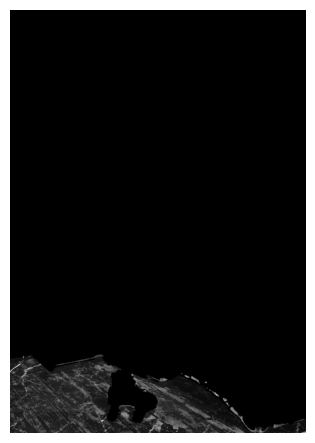

In [ ]:
# 10단계: 서버 점검 (이 노트북 안에서 직접 한 바퀴 돌려보기 — 벽 면 나누기까지)
from google.colab import files

def selftest(room_path, floor_urls=None, wall_urls=None, reference_urls=None, base=None, per_face=False):
    """방 사진 하나로 /rooms → (선택) /floors/sync, /walls/sync, /recommend → /generate를 순서대로 불러보고 결과를 저장해요.
    floor_urls / wall_urls: {"floor_001": "https://..."} 형태로 주면 그 목록부터 시험함
    per_face=True면 벽 면마다 다른 색을 칠해서 면이 제대로 나뉘었는지 눈으로 확인함."""
    base = base or f"http://127.0.0.1:{PORT}"
    headers = {"X-AI-Key": AI_SERVER_KEY} if AI_SERVER_KEY else {}
    show = lambda title, r: print(f"[{title}] {r.status_code}", (r.text[:200] if r.status_code >= 400 else "OK"))
    show("health", _requests.get(base + "/health"))
    if floor_urls:
        r = _requests.post(base + "/floors/sync", json={"items": [{"id": k, "url": v} for k, v in floor_urls.items()]}, headers=headers); show("floors/sync", r)
    if wall_urls:
        r = _requests.post(base + "/walls/sync", json={"items": [{"id": k, "url": v} for k, v in wall_urls.items()]}, headers=headers); show("walls/sync", r)
    with open(room_path, "rb") as f:
        r = _requests.post(base + "/rooms", files={"image": f}, headers=headers)
    show("rooms", r); info = r.json(); room_id = info["room_id"]
    print("  영역:", info["regions"])
    print("  벽 면:", info["wall_faces"], "| 모서리:", info["wall_split"], "| 자동으로 나눠짐:", info["wall_split_found"])
    for w in info["warnings"]:
        print("  ⚠️", w)
    materials = {"allWalls": {"hex": "#E8DCC8"}, "floor": {"id": next(iter(FLOOR_LIBRARY))}}      # 추천을 안 쓰거나 실패하면 이 기본값
    if reference_urls:
        r = _requests.post(base + "/recommend", json={"reference_urls": reference_urls}, headers=headers); show("recommend", r)
        if r.status_code == 200:
            p = r.json()["proposals"][0]
            print("  키워드:", r.json()["keywords_ko"], "| 첫 시안:", p["name"], p["wall"]["hex"], p["floor_id"])
            materials = {"allWalls": ({"id": p["wall_id"]} if p.get("wall_id") else {"hex": p["wall"]["hex"]}),
                         "floor": {"id": p["floor_id"]}}
    if per_face:                                       # 면마다 다른 색을 칠해서 면이 제대로 나뉘었는지 눈으로 보기
        materials = {**{name: {"hex": h} for name, h in zip(info["wall_faces"], ["#E8DCC8", "#C9D8E8", "#E8D0C9"])},
                     "floor": materials["floor"]}
    r = _requests.post(f"{base}/rooms/{room_id}/generate", json={"materials": materials, "options": {"reflect": 0.3, "pattern": WALL_PATTERN_REMOVE}}, headers=headers); show("generate", r)
    if r.status_code == 200:
        res = r.json(); open("selftest.jpg", "wb").write(base64.b64decode(res["image_base64"]))
        print("  적용:", res["applied"], "| 경고:", res["warnings"], "|", res["seconds"], "초")
        import matplotlib.pyplot as plt
        plt.figure(figsize=(8, 5.5)); plt.imshow(Image.open("selftest.jpg")); plt.axis("off"); plt.show()
    return room_id

print("[내 방 사진]을 올려주세요")
_room_file = list(files.upload().keys())[0]
_room_id = selftest(_room_file, per_face=True)       # 벽 면마다 다른 색 → 면이 잘 나뉘었는지 확인

# 벽 모서리를 직접 정해보기 (프론트에서 사용자가 선을 끌 때 쓰는 요청)
# _requests.post(f"http://127.0.0.1:{PORT}/rooms/{_room_id}/wall-split", json={"x": [400, 1500]},
#                headers={"X-AI-Key": AI_SERVER_KEY} if AI_SERVER_KEY else {}).json()

In [ ]:
print(abs)

<built-in function abs>
